<a href="https://colab.research.google.com/github/Developer-JayShah/2d-transform/blob/master/Team_6_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Shelf Readiness Audit: EDA of Amazon ESCI + Amazon Reviews 2023

**Project:** Reproducible Framework for Measuring Product-Data Effects on AI Shopping-Agent Recommendations (Team 6)

**Question this notebook answers:**
Do real product listings contain the information real shoppers ask for, in a form an AI shopping agent can use?

**Structure:**
- Part A: Baseline EDA
- Part B: AI Shelf Readiness Audit (new analyses)

## Step 1: Setup and download
- Raw data - Colab's local disk
- Results (tables, charts, numbers) Google Drive folder `capstone_eda`

In [2]:
# ============================================================
# STEP 1A: Libraries, folders, and a download helper
# ============================================================
import os, re, json, time, urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from google.colab import drive

# --- Folders ---
drive.mount('/content/drive')
RAW_DIR = "/content/raw_data"
OUT_DIR = "/content/drive/MyDrive/capstone_eda"        # results we keep (Google Drive)
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# --- Every reported number goes in here ---
STATS = {}

# --- Download helper: downloads once, skips if the file already exists ---
def download(url, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        print("Already downloaded:", os.path.basename(path))
        return
    print("Downloading", os.path.basename(path), "...")
    start = time.time()
    last_report = [0]

    def show_progress(blocks, block_size, total):
        done = blocks * block_size
        if total > 0 and done - last_report[0] > 500e6:
            last_report[0] = done
            print(f"  {done/1e9:.1f} of {total/1e9:.1f} GB")

    urllib.request.urlretrieve(url, path + ".part", show_progress)
    os.replace(path + ".part", path)
    print(f"  Done in {time.time()-start:.0f}s ({os.path.getsize(path)/1e9:.2f} GB)")

print("Setup complete")

Mounted at /content/drive
Setup complete


In [3]:
# ============================================================
# STEP 1B: Download both datasets
# ============================================================

# ESCI: Amazon Science (real shopper searches + relevance labels)
ESCI_URL = "https://media.githubusercontent.com/media/amazon-science/esci-data/main/shopping_queries_dataset/"
ESCI_EXAMPLES = f"{RAW_DIR}/shopping_queries_dataset_examples.parquet"
ESCI_PRODUCTS = f"{RAW_DIR}/shopping_queries_dataset_products.parquet"

# McAuley Amazon Reviews 2023: Electronics product metadata (price, ratings, specs)
MCAULEY_URL = ("https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/"
               "c9b9fe596c697ec468716f92345ff47ffe947278/raw/meta_categories/Electronics.jsonl")
MCAULEY_FILE = f"{RAW_DIR}/mcauley_Electronics.jsonl"

download(ESCI_URL + "shopping_queries_dataset_examples.parquet", ESCI_EXAMPLES)
download(ESCI_URL + "shopping_queries_dataset_products.parquet", ESCI_PRODUCTS)
download(MCAULEY_URL, MCAULEY_FILE)

print("\nAll downloads complete ")

  Done in 1s (0.05 GB)
  0.5 of 1.1 GB
  1.0 of 1.1 GB
  Done in 39s (1.11 GB)
  0.5 of 5.2 GB
  1.0 of 5.2 GB
  1.5 of 5.2 GB
  2.0 of 5.2 GB
  2.5 of 5.2 GB
  3.0 of 5.2 GB
  3.5 of 5.2 GB
  4.0 of 5.2 GB
  4.5 of 5.2 GB
  5.0 of 5.2 GB
  Done in 65s (5.25 GB)

All downloads complete 


# Part A: Baseline EDA

## Step 2: ESCI headphones subset
**Rule:**
- Keep only US searches (`product_locale = "us"`)
- Keep searches that mention headphones, earbuds, earphones, headsets, AirPods or EarPods
- Exclude VR headsets (VR, Oculus, Meta Quest, virtual reality)
- Keep every product that was judged for those searches

**Output:**
- `esci_pairs`: one row per (search, product, relevance label)
- `esci_products`: one row per product (title, brand, color, bullets, description)

In [4]:
# ============================================================
# STEP 2: ESCI headphones subset
# ============================================================

# --- 2.1 Words that make a search a "headphone search" ---
HEADPHONE_WORDS = re.compile(
    r"\b(head ?phones?|ear ?buds?|ear ?phones?|head ?sets?|air ?pods?|ear ?pods?)\b", re.I)
VR_WORDS = re.compile(r"\b(vr|oculus|virtual reality|meta quest|quest 2)\b", re.I)

def is_headphone_search(text):
    """True if the search mentions headphones AND is not about VR headsets."""
    return bool(HEADPHONE_WORDS.search(text)) and not VR_WORDS.search(text)

# --- 2.2 Load the searches (examples file) and keep only the US ---
examples = pd.read_parquet(ESCI_EXAMPLES, columns=[
    "query", "query_id", "product_id", "product_locale", "esci_label", "small_version", "split"])
us_pairs = examples[examples["product_locale"] == "us"]

# --- 2.3 Find the headphone searches ---
us_searches = us_pairs[["query_id", "query"]].drop_duplicates()
headphone_searches = us_searches[us_searches["query"].apply(is_headphone_search)]
esci_pairs = us_pairs[us_pairs["query_id"].isin(headphone_searches["query_id"])].copy()

# --- 2.4 Load only the products we need (file is 1.1 GB, so read in batches) ---
needed_ids = set(esci_pairs["product_id"])
parts = []
for batch in pq.ParquetFile(ESCI_PRODUCTS).iter_batches(batch_size=200_000):
    df = batch.to_pandas()
    parts.append(df[(df["product_locale"] == "us") & (df["product_id"].isin(needed_ids))])
esci_products = pd.concat(parts).drop_duplicates("product_id")

# --- 2.5 Save the numbers ---
STATS["esci"] = {
    "us_searches":     int(us_pairs["query_id"].nunique()),
    "us_pairs":        int(len(us_pairs)),
    "subset_searches": int(esci_pairs["query_id"].nunique()),
    "subset_pairs":    int(len(esci_pairs)),
    "subset_products": int(len(esci_products)),
    "subset_brands":   int(esci_products["product_brand"].replace("", pd.NA).dropna().nunique()),
}

# --- 2.6 Show the summary ---
summary = pd.DataFrame({
    "Measure": ["US searches (all)", "US search–product pairs (all)",
                "Headphone searches", "Headphone search–product pairs",
                "Headphone products", "Brands"],
    "Count": [STATS["esci"][k] for k in ["us_searches", "us_pairs", "subset_searches",
                                         "subset_pairs", "subset_products", "subset_brands"]],
})
summary["Count"] = summary["Count"].map("{:,}".format)
print("ESCI HEADPHONES SUBSET")
display(summary)

# --- 2.7 Save the subset to Google Drive (so we never rebuild it) ---
esci_pairs.to_parquet(f"{OUT_DIR}/esci_pairs.parquet", index=False)
esci_products.to_parquet(f"{OUT_DIR}/esci_products.parquet", index=False)

# --- 2.8 Look at a few real searches ---
print("\n10 random real headphone searches:")
for q in headphone_searches["query"].sample(10, random_state=42):
    print("  •", q)

del examples   # free memory

ESCI HEADPHONES SUBSET


,Measure,Count
0,US searches (all),"97,345"
1,US search–product pairs (all),"1,818,825"
2,Headphone searches,680
3,Headphone search–product pairs,"12,768"
4,Headphone products,"6,465"
5,Brands,"2,385"



10 random real headphone searches:
  • wireless earphone for running
  • turn airpods into wireless
  • airpod charging case
  • earphones
  • airpods case for tws i12
  • ps4 headset
  • cat ear kids headphones
  • apple usb audio adapter with 3.5mm speaker/headphone
  • wireless headset for office binaural
  • master dynamics headphones


## Step 3: Report style + A1. Relevance label mix
**Report style:** every figure follows one professional design:
insight title (the finding), subtitle (what is measured), numbers on the bars,
red only for problems, and a figure number + source line.

**A1 question:** Is our headphones subset representative of all US searches?
We compare the share of Exact / Substitute / Complement / Irrelevant labels.

In [18]:
# ============================================================
# STEP 3A: Report style for every figure
# ============================================================
CHART_DIR = f"{OUT_DIR}/figures"
os.makedirs(CHART_DIR, exist_ok=True)

# --- Colors ---
INK    = "#0F172A"   # titles, main text
MUTED  = "#64748B"   # subtitles, labels, source line
GRID   = "#E2E8F0"   # light grid lines
NAVY   = "#1E3A8A"   # main data color
BLUE   = "#3B82F6"   # second data color
LIGHT  = "#93C5FD"   # third data color
GRAY   = "#CBD5E1"   # neutral / "other"
RED    = "#DC2626"   # problems only (missing, broken, inconsistent)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 11, "text.color": INK,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": INK,
    "axes.edgecolor": GRID, "legend.frameon": False})
plt.rcParams["text.parse_math"] = False   # treat "$" as a normal dollar sign, not math

def style_axes(ax, grid=None):
    """Remove clutter. grid = 'x', 'y' or None."""
    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_visible(False)
    if grid == "x": ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    if grid == "y": ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

def finish(fig, fig_id, title, subtitle, source, filename):
    """Add insight title, subtitle, figure number + source, then save to Drive."""
    fig.text(0.02, 0.97, title, ha="left", va="top", fontsize=15, fontweight="bold", color=INK)
    fig.text(0.02, 0.89, subtitle, ha="left", va="top", fontsize=11, color=MUTED)
    fig.text(0.02, 0.02, f"Figure {fig_id}  |  Source: {source}", fontsize=9, color=MUTED)
    fig.tight_layout(rect=(0, 0.06, 1, 0.84))
    fig.savefig(f"{CHART_DIR}/{fig_id}_{filename}.png", dpi=220, facecolor="white")
    plt.show()

print("Report style ready ✅")

Report style ready ✅


,Headphones subset (%),All US searches (%)
esci_label,,
Exact,71.0,68.6
Substitute,21.0,20.3
Complement,3.7,2.2
Irrelevant,4.2,8.9


Median products judged per search: 16


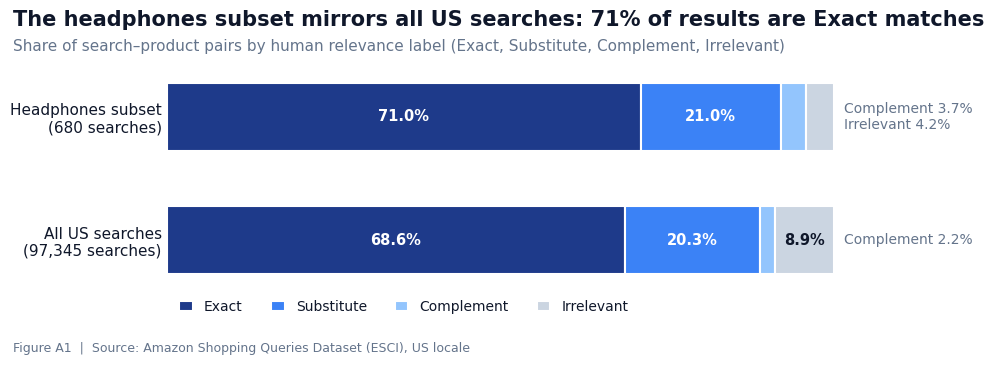

In [8]:
# ============================================================
# STEP 3B: A1. Relevance label mix (subset vs. all US)
# ============================================================
LABEL_NAMES  = {"E": "Exact", "S": "Substitute", "C": "Complement", "I": "Irrelevant"}
ORDER        = ["Exact", "Substitute", "Complement", "Irrelevant"]
LABEL_COLORS = {"Exact": NAVY, "Substitute": BLUE, "Complement": LIGHT, "Irrelevant": GRAY}

def label_share(pairs):
    """% of search–product pairs with each label."""
    share = pairs["esci_label"].map(LABEL_NAMES).value_counts(normalize=True) * 100
    return share.reindex(ORDER).round(1)

subset_share = label_share(esci_pairs)
us_share     = label_share(us_pairs)
median_per_search = float(esci_pairs.groupby("query_id").size().median())

STATS["esci"]["label_share_subset"] = subset_share.to_dict()
STATS["esci"]["label_share_us"]     = us_share.to_dict()
STATS["esci"]["median_products_per_search"] = median_per_search

# --- Table ---
display(pd.DataFrame({"Headphones subset (%)": subset_share,
                      "All US searches (%)": us_share}))
print(f"Median products judged per search: {median_per_search:.0f}")

# --- Figure: 100% stacked bars ---
rows = [f"Headphones subset\n({STATS['esci']['subset_searches']:,} searches)",
        f"All US searches\n({STATS['esci']['us_searches']:,} searches)"]
data = pd.DataFrame([subset_share, us_share], index=rows)

fig, ax = plt.subplots(figsize=(10, 3.6))
y = [1, 0]
left = np.zeros(2)
small = {1: [], 0: []}                       # small segments, labeled outside the bar

for label in ORDER:
    values = data[label].values
    ax.barh(y, values, left=left, height=0.55, color=LABEL_COLORS[label],
            edgecolor="white", linewidth=1.5, label=label)
    for yi, start, v in zip(y, left, values):
        if v >= 6:                           # big enough: number inside the segment
            ax.text(start + v / 2, yi, f"{v:.1f}%", ha="center", va="center", fontsize=10.5,
                    fontweight="bold", color="white" if label in ["Exact", "Substitute"] else INK)
        else:                                # too small: list it to the right
            small[yi].append(f"{label} {v:.1f}%")
    left += values

for yi, items in small.items():
    if items:
        ax.text(101.5, yi, "\n".join(items), va="center", fontsize=10, color=MUTED)

ax.set_yticks(y, rows)
ax.set_xlim(0, 120)                          # space on the right for small labels
ax.set_xticks([])
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.02), handlelength=1, fontsize=10)
style_axes(ax)

finish(fig, "A1",
       title=f"The headphones subset mirrors all US searches: {subset_share['Exact']:.0f}% of results are Exact matches",
       subtitle="Share of search–product pairs by human relevance label (Exact, Substitute, Complement, Irrelevant)",
       source="Amazon Shopping Queries Dataset (ESCI), US locale",
       filename="label_mix")

**So what?**
- **Research:** The headphones subset has almost the same label mix as all US searches,
  so our findings come from a representative sample, not a biased one.
- **Business:** A typical search shows ~16 judged products: a realistic candidate list
  for an AI shopping agent to compare.

## Step 4: A2. Missing fields in product listings (ESCI)
**Question:** How often are basic product fields empty in real headphone listings?
- A field counts as **empty** if it is blank or contains only placeholders ("", "{}", "[]", "None", "nan")
- We also measure how many listings are **fully complete** (all 5 fields filled)

,Empty (%)
Description,46.6
Color,20.5
Bullet points,16.5
Brand,0.7
Title,0.0


Listings with ALL 5 fields filled: 45.8%


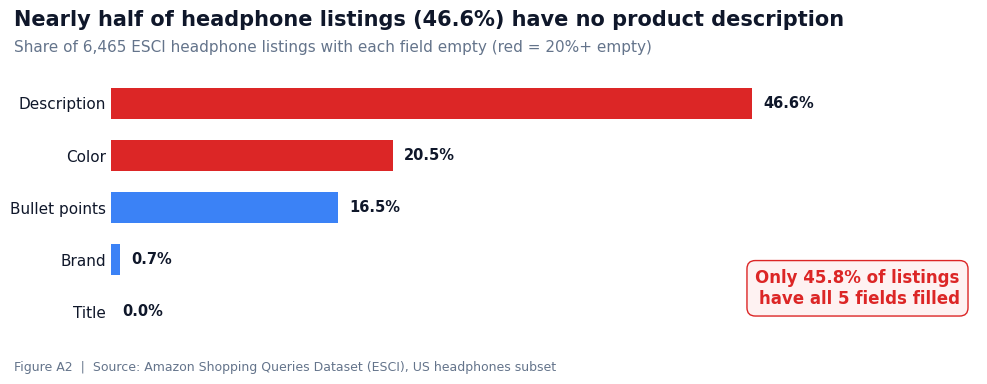

In [9]:
# ============================================================
# STEP 4: A2. Missing fields in ESCI listings
# ============================================================

# --- 4.1 What counts as "empty" (same rule used everywhere in this notebook) ---
def is_empty(series):
    """True where a value is missing or only a placeholder."""
    return series.isna() | series.astype(str).str.strip().isin(["", "{}", "None", "nan", "[]"])

ESCI_FIELDS = {"Title": "product_title", "Bullet points": "product_bullet_point",
               "Description": "product_description", "Brand": "product_brand",
               "Color": "product_color"}

# --- 4.2 % empty per field, and % fully complete ---
missing = pd.Series({name: is_empty(esci_products[col]).mean() * 100
                     for name, col in ESCI_FIELDS.items()}).round(1).sort_values(ascending=False)

empty_matrix = esci_products[list(ESCI_FIELDS.values())].apply(is_empty)
complete_pct = round(float((~empty_matrix.any(axis=1)).mean() * 100), 1)

STATS["esci"]["missing_pct"] = missing.to_dict()
STATS["esci"]["complete_all_fields_pct"] = complete_pct

# --- 4.3 Table ---
display(missing.rename("Empty (%)").to_frame())
print(f"Listings with ALL 5 fields filled: {complete_pct}%")

# --- 4.4 Figure: % empty per field (red = serious gap, 20%+ empty) ---
fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(missing))[::-1]
colors = [RED if v >= 20 else BLUE for v in missing.values]
ax.barh(y, missing.values, height=0.6, color=colors)
for yi, v in zip(y, missing.values):
    ax.text(v + 0.8, yi, f"{v:.1f}%", va="center", fontsize=10.5, fontweight="bold")
ax.set_yticks(y, missing.index)
ax.set_xlim(0, max(missing.max() * 1.35, 10))
ax.set_xticks([])

# key number in a callout box
ax.text(0.98, 0.12, f"Only {complete_pct}% of listings\nhave all 5 fields filled",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=12, fontweight="bold", color=RED,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#FEF2F2", edgecolor=RED, linewidth=1))
style_axes(ax)

finish(fig, "A2",
       title=f"Nearly half of headphone listings ({missing['Description']:.1f}%) have no product description",
       subtitle=f"Share of {STATS['esci']['subset_products']:,} ESCI headphone listings with each field empty (red = 20%+ empty)",
       source="Amazon Shopping Queries Dataset (ESCI), US headphones subset",
       filename="esci_missing_fields")

## Step 5: A3. Text length and HTML clutter
**Question:** How much text does an AI agent have to read per listing, and how clean is it?
- Word count per field (HTML tags removed before counting; empty fields excluded)
- Share of non-empty descriptions that contain raw HTML code (e.g. `<br>`, `<p>`, `<b>`)

,Listings (non-empty),Median words,25th percentile,75th percentile
Title,6465,23,18,27
Bullet points,5398,148,87,205
Description,3453,129,58,210


Descriptions containing raw HTML: 68.1%

Example of a real description with HTML (first 200 characters):
   <b>Features:</b><br> 1. Smooth-with silicone oil, keep away from dust and dirty.<br> 2. Slim and thin- can hardly feel its existence.<br> 3. Made of high quality silicone with silicone oil on surface, ...


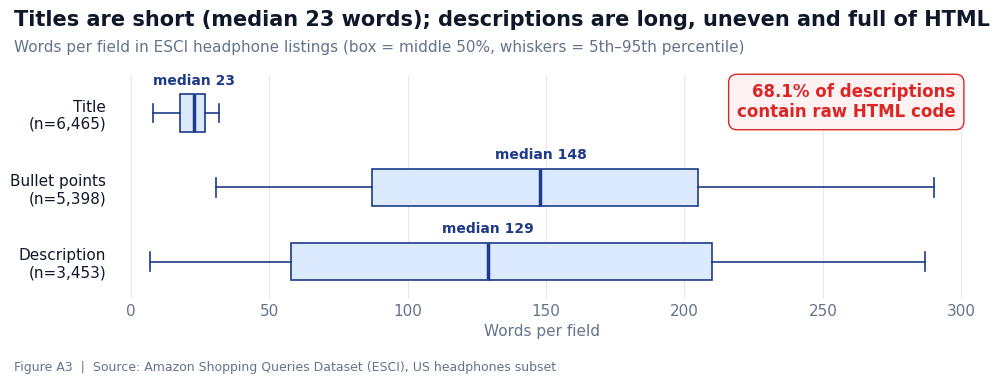

In [11]:
# ============================================================
# STEP 5: A3. Text length and HTML clutter (ESCI)
# ============================================================

# --- 5.1 Count words per field (remove HTML tags first, skip empty fields) ---
def word_count(series):
    text = series.fillna("").str.replace(r"<[^>]+>", " ", regex=True)
    counts = text.str.split().str.len()
    return counts[counts > 0]

TEXT_FIELDS = ["Title", "Bullet points", "Description"]
LENS = {name: word_count(esci_products[ESCI_FIELDS[name]]) for name in TEXT_FIELDS}

# --- 5.2 Share of descriptions with raw HTML code ---
desc = esci_products["product_description"].fillna("")
desc = desc[desc.str.strip() != ""]
has_html = desc.str.contains(r"<[a-zA-Z/][^>]*>", regex=True)
html_pct = round(float(has_html.mean() * 100), 1)

STATS["esci"]["words_median"] = {k: float(v.median()) for k, v in LENS.items()}
STATS["esci"]["description_has_html_pct"] = html_pct

# --- 5.3 Table ---
length_table = pd.DataFrame({
    "Listings (non-empty)": {k: len(v) for k, v in LENS.items()},
    "Median words":         {k: int(v.median()) for k, v in LENS.items()},
    "25th percentile":      {k: int(v.quantile(0.25)) for k, v in LENS.items()},
    "75th percentile":      {k: int(v.quantile(0.75)) for k, v in LENS.items()},
})
display(length_table)
print(f"Descriptions containing raw HTML: {html_pct}%")

# --- 5.4 One real example of HTML clutter ---
print("\nExample of a real description with HTML (first 200 characters):")
print("  ", desc[has_html].iloc[0][:200], "...")

# --- 5.5 Figure: word counts per field (box = middle 50%, whiskers = 5th–95th percentile) ---
fig, ax = plt.subplots(figsize=(10, 3.8))
box_style = dict(widths=0.5, patch_artist=True, showfliers=False, whis=(5, 95),
                 medianprops=dict(color=NAVY, linewidth=2.5),
                 boxprops=dict(facecolor="#DBEAFE", edgecolor=NAVY, linewidth=1.2),
                 whiskerprops=dict(color=NAVY, linewidth=1.2),
                 capprops=dict(color=NAVY, linewidth=1.2))
data = [LENS[k].tolist() for k in TEXT_FIELDS][::-1]          # Title on top
try:
    ax.boxplot(data, orientation="horizontal", **box_style)  # newer matplotlib
except TypeError:
    ax.boxplot(data, vert=False, **box_style)                # older matplotlib

ax.set_yticks([1, 2, 3], [f"{k}\n(n={len(LENS[k]):,})" for k in TEXT_FIELDS][::-1])
for i, k in enumerate(TEXT_FIELDS[::-1], start=1):
    ax.text(LENS[k].median(), i + 0.38, f"median {LENS[k].median():.0f}",
            ha="center", fontsize=10, fontweight="bold", color=NAVY)
ax.set_xlabel("Words per field")

ax.text(0.98, 0.97, f"{html_pct}% of descriptions\ncontain raw HTML code",
        transform=ax.transAxes, ha="right", va="top", fontsize=12, fontweight="bold", color=RED,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#FEF2F2", edgecolor=RED, linewidth=1))
style_axes(ax, grid="x")

finish(fig, "A3",
       title=f"Titles are short (median {LENS['Title'].median():.0f} words); descriptions are long, uneven and full of HTML",
       subtitle="Words per field in ESCI headphone listings (box = middle 50%, whiskers = 5th–95th percentile)",
       source="Amazon Shopping Queries Dataset (ESCI), US headphones subset",
       filename="text_length_html")

**So what?**
- **Research:** An AI agent reads short titles but long, uneven descriptions, and most descriptions
  contain raw HTML code: noise the agent must ignore. HTML clutter is a real example of the
  "different format" problem we test in the experiment.
- **Business:** Key facts placed only in the description are buried in long, messy text.
  Important facts (battery, compatibility, price) are safer in the title or bullet points.

## Step 6: McAuley headphones subset (Amazon Reviews 2023)
**Selection rule:**
- Read all Electronics products (5.25 GB, line by line)
- Keep a product if its category or title says headphones / earbuds / earphones / headsets / AirPods / in-ear monitors
- Remove accessories (cases, ear pads, cables, chargers, stands, ...) and VR headsets

**What McAuley adds that ESCI lacks:** price, average rating, number of ratings, and a specs table (`details`).

In [12]:
# ============================================================
# STEP 6: McAuley headphones subset (about 10–15 minutes)
# ============================================================

# --- 6.1 Rules: what is a headphone, what is an accessory, what is VR ---
MC_HEADPHONE_WORDS = re.compile(
    r"\b(head ?phones?|ear ?buds?|ear ?phones?|head ?sets?|air ?pods?|in-ear monitors?)\b", re.I)
ACCESSORY_WORDS = re.compile(
    r"\b(case|cover|replacement|cushions?|ear ?pads?|ear ?tips?|adapter|stand|hanger|holder|cable|cord|"
    r"splitter|extension|amplifier|amp|skin|sticker|charger|charging dock|foam|protector|strap|clip|hook|mount|repair)\b", re.I)
MC_VR_WORDS = re.compile(r"\b(vr|oculus|virtual reality|quest)\b", re.I)

def is_headphone_product(title, categories):
    """Keep real headphones; drop accessories and VR headsets."""
    in_category        = bool(re.search(r"headphone|earbud|earphone|headset", categories, re.I))
    looks_like_one     = in_category or bool(MC_HEADPHONE_WORDS.search(title))
    mentions_headphone = bool(MC_HEADPHONE_WORDS.search(title + " " + categories))
    is_accessory       = bool(ACCESSORY_WORDS.search(title))
    is_vr              = bool(MC_VR_WORDS.search(title))
    return looks_like_one and mentions_headphone and not is_accessory and not is_vr

# --- 6.2 Helpers to clean raw values ---
def as_list(x):
    if x is None: return []
    return [str(i) for i in x if i is not None] if isinstance(x, list) else [str(x)]

def as_dict(x):
    if isinstance(x, dict): return x
    if isinstance(x, str) and x.strip().startswith("{"):
        try: return json.loads(x)
        except Exception: return {}
    return {}

def as_price(x):
    """Turn a raw price into a number; None if missing or invalid."""
    if isinstance(x, (int, float)):
        return float(x) if x > 0 else None
    m = re.search(r"\d[\d,]*\.?\d*", str(x or ""))
    try:
        value = float(m.group(0).replace(",", "")) if m else None
    except ValueError:
        value = None
    return value if value and value > 0 else None

# --- 6.3 Read the 5.25 GB file line by line, keep only headphones ---
rows, n_read = [], 0
with open(MCAULEY_FILE, "rt", encoding="utf-8") as f:
    for line in f:
        n_read += 1
        if n_read % 250_000 == 0:
            print(f"  {n_read:,} products read, {len(rows):,} headphones kept")
        try:
            r = json.loads(line)
        except json.JSONDecodeError:
            continue
        title = r.get("title") or ""
        categories = " > ".join(as_list(r.get("categories")))
        if not is_headphone_product(title, categories):
            continue
        rows.append({
            "parent_asin":    r.get("parent_asin"),
            "title":          title,
            "store":          r.get("store") or "",
            "price":          as_price(r.get("price")),
            "average_rating": r.get("average_rating"),
            "rating_number":  r.get("rating_number"),
            "features":       " | ".join(as_list(r.get("features"))),
            "description":    " ".join(as_list(r.get("description"))),
            "categories":     categories,
            "details":        json.dumps(as_dict(r.get("details")), ensure_ascii=False),
        })

mc_products = pd.DataFrame(rows).drop_duplicates("parent_asin")
del rows

# --- 6.4 Save the numbers and the subset ---
STATS["mcauley"] = {"electronics_products_read": int(n_read),
                    "headphones_kept": int(len(mc_products))}
mc_products.to_parquet(f"{OUT_DIR}/mcauley_products.parquet", index=False)

summary = pd.DataFrame({
    "Measure": ["Electronics products read", "Headphones kept"],
    "Count": [f"{n_read:,}", f"{len(mc_products):,}"]})
print("\nMcAULEY HEADPHONES SUBSET")
display(summary)

print("\n10 random headphone titles:")
for t in mc_products["title"].sample(10, random_state=42):
    print("  •", t[:110])

  250,000 products read, 10,316 headphones kept
  500,000 products read, 20,771 headphones kept
  750,000 products read, 31,252 headphones kept
  1,000,000 products read, 41,831 headphones kept
  1,250,000 products read, 52,143 headphones kept
  1,500,000 products read, 61,797 headphones kept

McAULEY HEADPHONES SUBSET


,Measure,Count
0,Electronics products read,"1,610,012"
1,Headphones kept,"65,558"



10 random headphone titles:
  • Géneric [Upgrade] Wireless Bluetooth Headset LED Power Display Binaural 5.2 in-Ear Type for Bluetooth-Enabled 
  • Wired in-Ear Headphones, Magnetic Microphones Earphones Noise Isolating Workout Running Commute Gaming Tangle 
  • Geemarc Hearing Aid Headphone (CLA3)
  • 【Upgraded】 Emergency Weather Solar Crank Radio with Earphone Jack and Charging Indicator, 2000mAh Battery Powe
  • Rechargeable Bluetooth Wireless Headset for Tablet Smart Phone iPod mp4 tv iPad Gaming pc Laptop Desktop (Blac
  • Merkury Innovations MI-HM100-500 Artist Suede Headphones - Purple
  • Herlitz M Nib My Pen Fountain Pen - Blue/Lemon
  • Retractable Earphones Headphones Compatible with Motorola Moto Z4, Hands-Free Headset 3.5mm w Mic Earbuds Earp
  • Creative Outlier Sports Wireless Sweatproof in-Ears (Orange)
  • PHILIPS SHQ1300LF


## Step 7: A4. Key facts stated in listings + A5. How "hours" are written
**A4 question:** How often do listings state the facts shoppers care about?
A fact counts as **stated** if it appears anywhere in the listing text
(ESCI: title + bullets + description; McAuley: title + features + description + specs table).

**A5 question:** When listings state battery hours, how consistently are they written?
(e.g. "40 hours" vs "40H" vs "40hrs")

,ESCI (%),McAuley (%)
Bluetooth / wireless,48.8,48.9
Hours (battery / charging),32.3,24.4
Noise cancelling,30.6,34.5
iPhone / Android compatibility,27.3,28.2
Bluetooth version,15.5,13.8
Water resistance (IPX),10.2,9.2


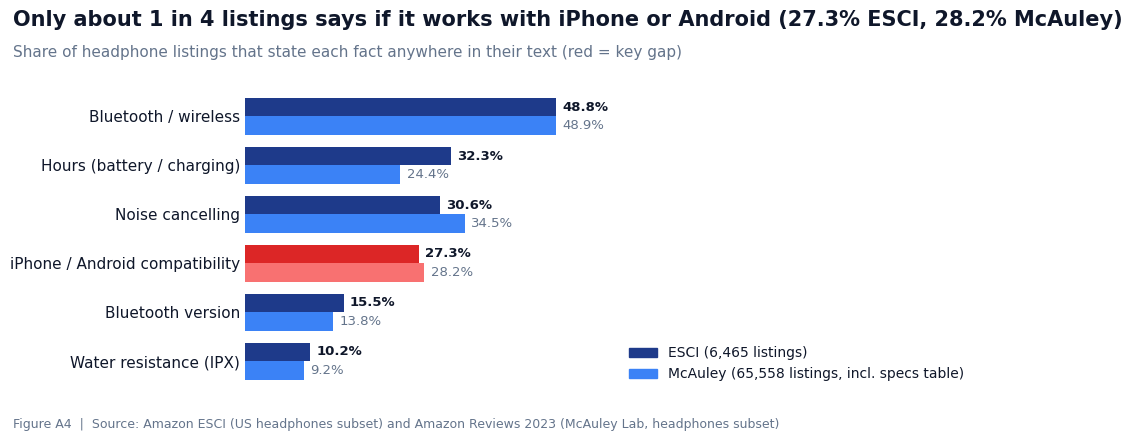

In [15]:
# ============================================================
# STEP 7A: A4. Key facts stated in listings (ESCI vs McAuley)
# ============================================================
from matplotlib.patches import Patch

# --- 7.1 Patterns that detect each fact in the text ---
FACTS = {
    "Bluetooth / wireless":           r"bluetooth|wireless",
    "Hours (battery / charging)":     r"\d+(?:\.\d+)?\s*-?\s*(?:hours?|hrs?|h)\b(?!z)",
    "Noise cancelling":               r"noise[\s-]*(?:cancel|reduc|isolat)|\banc\b",
    "iPhone / Android compatibility": r"iphone|ios\b|android",
    "Bluetooth version":              r"bluetooth\s*(?:v|version)?\s*\d\.\d|\bbt\s*\d\.\d|\bv\d\.\d",
    "Water resistance (IPX)":         r"\bipx?\s*-?\s*\d",
}

# --- 7.2 All listing text in lowercase, one string per product ---
esci_text = (esci_products["product_title"].fillna("") + " " +
             esci_products["product_bullet_point"].fillna("") + " " +
             esci_products["product_description"].fillna("")).str.lower()
mc_text = (mc_products["title"] + " " + mc_products["features"] + " " +
           mc_products["description"] + " " + mc_products["details"]).str.lower()

# --- 7.3 % of listings stating each fact ---
facts_table = pd.DataFrame({
    "ESCI (%)":    {k: round(float(esci_text.str.contains(p, regex=True).mean() * 100), 1) for k, p in FACTS.items()},
    "McAuley (%)": {k: round(float(mc_text.str.contains(p, regex=True).mean() * 100), 1) for k, p in FACTS.items()},
}).sort_values("ESCI (%)", ascending=False)

STATS["esci"]["fact_stated_pct"]    = facts_table["ESCI (%)"].to_dict()
STATS["mcauley"]["fact_stated_pct"] = facts_table["McAuley (%)"].to_dict()
display(facts_table)

# --- 7.4 Figure: grouped bars (compatibility highlighted as the key gap) ---
COMPAT = "iPhone / Android compatibility"
fig, ax = plt.subplots(figsize=(10, 4.4))
y = np.arange(len(facts_table))[::-1]
h = 0.38
for yi, (fact, row) in zip(y, facts_table.iterrows()):
    c1, c2 = (RED, "#F87171") if fact == COMPAT else (NAVY, BLUE)
    ax.barh(yi + h/2, row["ESCI (%)"], height=h, color=c1)
    ax.barh(yi - h/2, row["McAuley (%)"], height=h, color=c2)
    ax.text(row["ESCI (%)"] + 1, yi + h/2, f"{row['ESCI (%)']:.1f}%", va="center", fontsize=9.5, fontweight="bold")
    ax.text(row["McAuley (%)"] + 1, yi - h/2, f"{row['McAuley (%)']:.1f}%", va="center", fontsize=9.5, color=MUTED)
ax.set_yticks(y, facts_table.index)
ax.set_xlim(0, 115)
ax.set_xticks([])

# legend with the correct colors
ax.legend(handles=[Patch(color=NAVY, label=f"ESCI ({len(esci_products):,} listings)"),
                   Patch(color=BLUE, label=f"McAuley ({len(mc_products):,} listings, incl. specs table)")],
          loc="lower right", fontsize=10)
style_axes(ax)

e, m = facts_table.loc[COMPAT, "ESCI (%)"], facts_table.loc[COMPAT, "McAuley (%)"]
finish(fig, "A4",
       title=f"Only about 1 in 4 listings says if it works with iPhone or Android ({e:.1f}% ESCI, {m:.1f}% McAuley)",
       subtitle="Share of headphone listings that state each fact anywhere in their text (red = key gap)",
       source="Amazon ESCI (US headphones subset) and Amazon Reviews 2023 (McAuley Lab, headphones subset)",
       filename="facts_stated")

,Listings
“40 hours”,1539
“40H”,350
“40-hour”,201
“40hrs”,162
“40 hrs”,105
“40hours”,38
“40 H”,14
“40-hrs”,12


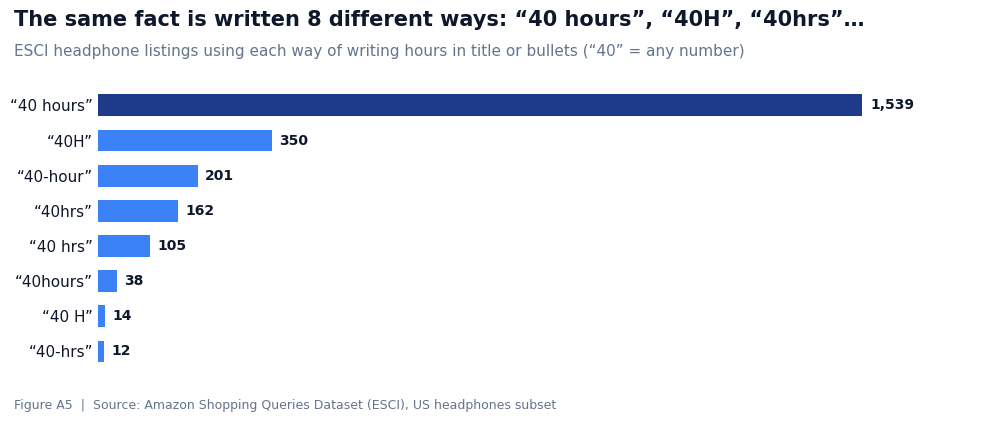

In [14]:
# ============================================================
# STEP 7B: A5. How "hours" are written (ESCI title + bullets)
# ============================================================
HOURS_PATTERN = re.compile(r"(\d+(?:\.\d+)?)(\s*-?\s*)(hours?|hrs?|h)\b(?!z)", re.I)

def format_of(match):
    """Turn a match like '40 hrs' into a format label like '40 hrs' ('40' stands for any number)."""
    sep, unit = match.group(2), match.group(3).lower()
    unit = "hours" if unit.startswith("hour") else ("hrs" if unit.startswith("hr") else "H")
    sep = "-" if "-" in sep else (" " if sep else "")
    return "40" + sep + unit

format_counts = {}
for text in esci_products["product_title"].fillna("") + " " + esci_products["product_bullet_point"].fillna(""):
    for fmt in {format_of(m) for m in HOURS_PATTERN.finditer(text)}:   # count each format once per listing
        format_counts[fmt] = format_counts.get(fmt, 0) + 1

formats = pd.Series(format_counts).sort_values(ascending=False)
formats.index = [f"“{'40-hour' if k == '40-hours' else k}”" for k in formats.index]
STATS["esci"]["hours_formats"] = formats.to_dict()
STATS["esci"]["hours_format_count"] = int(len(formats))
display(formats.rename("Listings").to_frame())

# --- Figure ---
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(formats))[::-1]
ax.barh(y, formats.values, height=0.62, color=[NAVY] + [BLUE] * (len(formats) - 1))
for yi, v in zip(y, formats.values):
    ax.text(v + formats.max() * 0.01, yi, f"{v:,}", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(y, formats.index)
ax.set_xlim(0, formats.max() * 1.15)
ax.set_xticks([])
style_axes(ax)

finish(fig, "A5",
       title=f"The same fact is written {len(formats)} different ways: “40 hours”, “40H”, “40hrs”…",
       subtitle="ESCI headphone listings using each way of writing hours in title or bullets (“40” = any number)",
       source="Amazon Shopping Queries Dataset (ESCI), US headphones subset",
       filename="hours_formats")

**So what?**
- **Research:** Compatibility, a fact shoppers often need, is stated by only ~1 in 4 listings in BOTH datasets,
  so the gap is real, not a quirk of one dataset. And the same fact (hours) appears in 8 formats:
  real evidence for the "different format" condition in our experiment.
- **Business:** If a listing never says "works with iPhone", an AI agent cannot recommend it for an iPhone user.
  Writing key facts in one standard format makes them easier for AI agents to read and compare.

,Empty (%)
Price,76.7
Description,43.7
Features,27.3
Specs table,0.9
Store / brand,0.4
Title,0.0
Rating,0.0


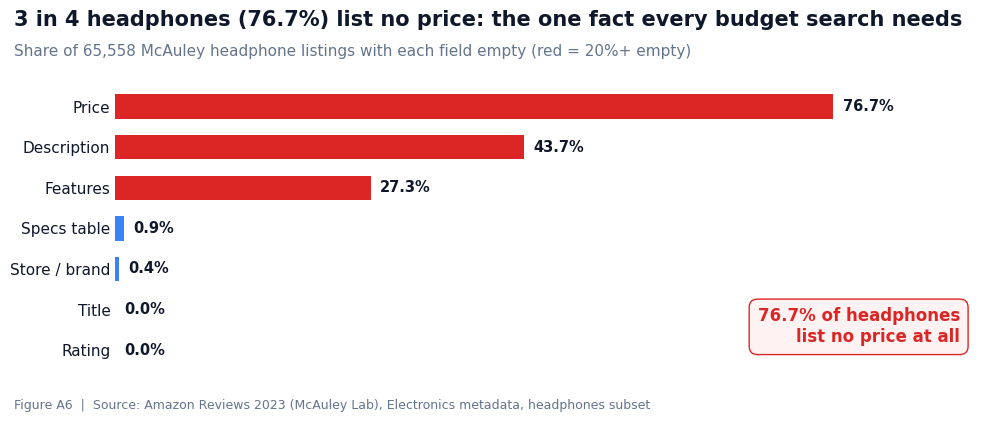

In [16]:
# ============================================================
# STEP 8: A6. Missing fields in McAuley listings
# ============================================================
MC_FIELDS = {"Title": "title", "Features": "features", "Description": "description",
             "Price": "price", "Store / brand": "store", "Specs table": "details",
             "Rating": "average_rating"}

mc_missing = pd.Series({name: is_empty(mc_products[col]).mean() * 100
                        for name, col in MC_FIELDS.items()}).round(1).sort_values(ascending=False)
STATS["mcauley"]["missing_pct"] = mc_missing.to_dict()

display(mc_missing.rename("Empty (%)").to_frame())

# --- Figure (red = 20%+ empty) ---
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(mc_missing))[::-1]
ax.barh(y, mc_missing.values, height=0.6, color=[RED if v >= 20 else BLUE for v in mc_missing.values])
for yi, v in zip(y, mc_missing.values):
    ax.text(v + 1, yi, f"{v:.1f}%", va="center", fontsize=10.5, fontweight="bold")
ax.set_yticks(y, mc_missing.index)
ax.set_xlim(0, max(mc_missing.max() * 1.2, 10))
ax.set_xticks([])

price_missing = mc_missing["Price"]
ax.text(0.98, 0.10, f"{price_missing:.1f}% of headphones\nlist no price at all",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=12, fontweight="bold", color=RED,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#FEF2F2", edgecolor=RED, linewidth=1))
style_axes(ax)

finish(fig, "A6",
       title=f"3 in 4 headphones ({price_missing:.1f}%) list no price: the one fact every budget search needs",
       subtitle=f"Share of {len(mc_products):,} McAuley headphone listings with each field empty (red = 20%+ empty)",
       source="Amazon Reviews 2023 (McAuley Lab), Electronics metadata, headphones subset",
       filename="mcauley_missing_fields")

**So what?**
- **Research:** Price is the most-used constraint in shopping ("under $100"), yet 3 in 4 listings
  in the public metadata have no price. Our pilot showed what happens then: when price is missing,
  the AI agent excludes the product (100% → 0%).
- **Business:** A product without a visible price is effectively invisible to budget-based
  AI recommendations, however good the product is.
- **Note:** missing price may partly reflect products that were unavailable when the data was collected.

## Step 9: A7. Price and ratings (McAuley)
**Questions:**
- (a) For listings that DO have a price, how expensive are headphones? (relevant for "under $100" tasks)
- (b) How much social proof (number of ratings) do listings have?

,Value
Listings with a price,"15,277"
Median price,$29.99
Middle 50% of prices,$16.98 – $65.89
Under $50,69.5%
Under $100,84.8%
Under $250,95.3%
Median star rating,3.9
Median number of ratings,17
Fewer than 10 ratings,39.3%


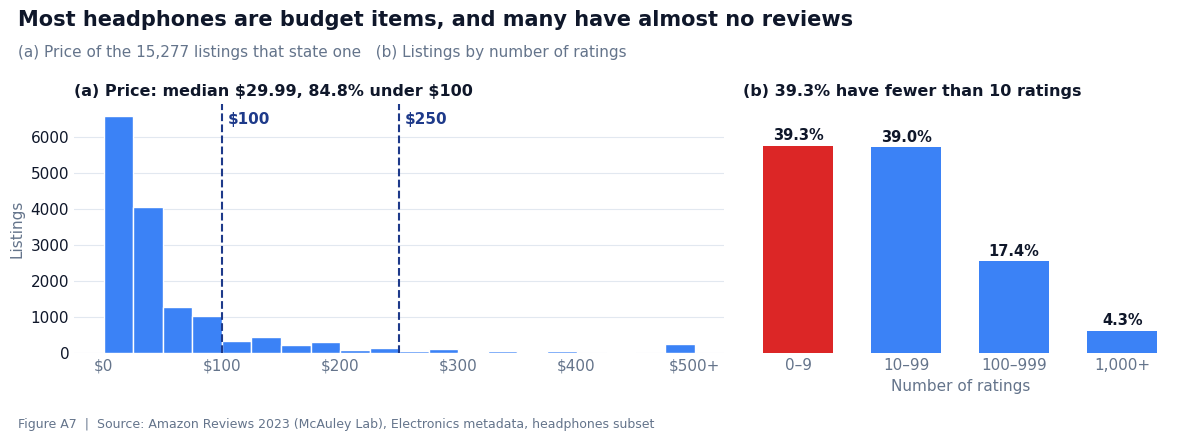

In [19]:
# ============================================================
# STEP 9: A7. Price and ratings (McAuley)
# ============================================================

# --- 9.1 Price (only listings that have one) ---
prices = mc_products["price"].dropna()
STATS["mcauley"]["price"] = {
    "n_with_price":  int(len(prices)),
    "median":        round(float(prices.median()), 2),
    "q1":            round(float(prices.quantile(0.25)), 2),
    "q3":            round(float(prices.quantile(0.75)), 2),
    "under_50_pct":  round(float((prices < 50).mean() * 100), 1),
    "under_100_pct": round(float((prices < 100).mean() * 100), 1),
    "under_250_pct": round(float((prices < 250).mean() * 100), 1),
}

# --- 9.2 Ratings ---
n_ratings = mc_products["rating_number"].dropna()
STATS["mcauley"]["rating"] = {
    "median_rating":        float(mc_products["average_rating"].dropna().median()),
    "median_n_ratings":     float(n_ratings.median()),
    "pct_under_10_ratings": round(float((n_ratings < 10).mean() * 100), 1),
}

P, R = STATS["mcauley"]["price"], STATS["mcauley"]["rating"]
display(pd.DataFrame({
    "Value": [f"{P['n_with_price']:,}", f"${P['median']}", f"${P['q1']} – ${P['q3']}",
              f"{P['under_50_pct']}%", f"{P['under_100_pct']}%", f"{P['under_250_pct']}%",
              f"{R['median_rating']}", f"{R['median_n_ratings']:.0f}", f"{R['pct_under_10_ratings']}%"]},
    index=["Listings with a price", "Median price", "Middle 50% of prices",
           "Under $50", "Under $100", "Under $250",
           "Median star rating", "Median number of ratings", "Fewer than 10 ratings"]))

# --- 9.3 Rating-count groups ---
groups = pd.cut(n_ratings, bins=[0, 10, 100, 1000, np.inf], right=False,
                labels=["0–9", "10–99", "100–999", "1,000+"])
group_share = (groups.value_counts(normalize=True).sort_index() * 100).round(1)

# --- 9.4 Figure: two panels side by side ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})

# (a) price distribution
ax1.hist(prices.clip(upper=500), bins=np.arange(0, 525, 25), color=BLUE, edgecolor="white")
for limit in (100, 250):
    ax1.axvline(limit, color=NAVY, linestyle="--", linewidth=1.5)
    ax1.text(limit + 5, ax1.get_ylim()[1] * 0.92, f"${limit}", color=NAVY, fontweight="bold")
ax1.set_xticks(range(0, 501, 100), [f"${x}" for x in range(0, 401, 100)] + ["$500+"])
ax1.set_ylabel("Listings")
ax1.set_title(f"(a) Price: median ${P['median']:.2f}, {P['under_100_pct']:.1f}% under $100",
              loc="left", fontsize=11.5, fontweight="bold", color=INK)
style_axes(ax1, grid="y")

# (b) number of ratings
colors = [RED] + [BLUE] * (len(group_share) - 1)
ax2.bar(group_share.index.astype(str), group_share.values, color=colors, width=0.65)
for i, v in enumerate(group_share.values):
    ax2.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=10.5, fontweight="bold")
ax2.set_ylim(0, group_share.max() * 1.2)
ax2.set_yticks([])
ax2.set_xlabel("Number of ratings")
ax2.set_title(f"(b) {R['pct_under_10_ratings']:.1f}% have fewer than 10 ratings",
              loc="left", fontsize=11.5, fontweight="bold", color=INK)
style_axes(ax2)

finish(fig, "A7",
       title="Most headphones are budget items, and many have almost no reviews",
       subtitle=f"(a) Price of the {P['n_with_price']:,} listings that state one   (b) Listings by number of ratings",
       source="Amazon Reviews 2023 (McAuley Lab), Electronics metadata, headphones subset",
       filename="price_ratings")

## Step 10: A8. What the specs tables actually contain (McAuley)
**Question:** McAuley listings have a structured specs table (`details`). Which specs appear most often,
and are they the facts shoppers need, or catalog/admin information?
- Blue = shopper-relevant spec (connectivity, form factor, noise control, battery, compatibility, ...)
- Gray = admin / catalog info (dates, model numbers, manufacturer, ...)

,Listings with this spec (%)
Date First Available,94.4
Manufacturer,91.5
Item Weight,86.4
Brand,78.9
Connectivity Technology,66.3
Form Factor,65.6
Item model number,64.8
Color,63.9
Is Discontinued By Manufacturer,51.5
Product Dimensions,49.9


Listings with ANY battery spec in their specs table: 0.9%
Battery spec in the top 12: False


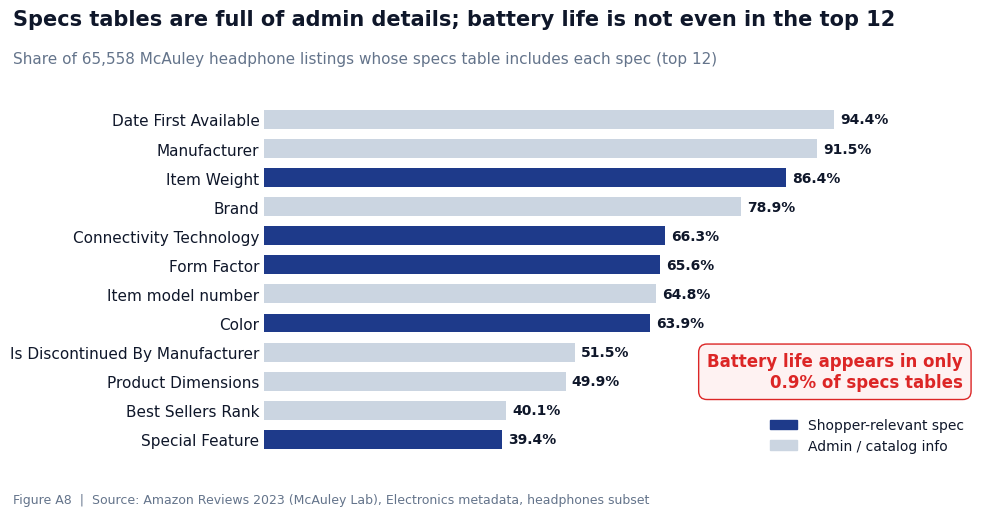

In [21]:
# ============================================================
# STEP 10: A8. What the specs tables contain (McAuley)
# ============================================================
from matplotlib.patches import Patch

# --- 10.1 Count how often each spec name appears ---
key_counts = {}
for d in mc_products["details"]:
    for key in json.loads(d):
        key_counts[key] = key_counts.get(key, 0) + 1

key_pct = (pd.Series(key_counts) / len(mc_products) * 100).round(1).sort_values(ascending=False)
top12 = key_pct.head(12)
STATS["mcauley"]["top_detail_keys_pct"] = top12.to_dict()

# --- 10.2 How often is battery life in the specs table at all? ---
has_battery_spec = mc_products["details"].apply(
    lambda d: any("battery" in k.lower() for k in json.loads(d)))
battery_spec_pct = round(float(has_battery_spec.mean() * 100), 1)
battery_in_top12 = any("battery" in k.lower() for k in top12.index)
STATS["mcauley"]["battery_spec_pct"] = battery_spec_pct

display(top12.rename("Listings with this spec (%)").to_frame())
print(f"Listings with ANY battery spec in their specs table: {battery_spec_pct}%")
print(f"Battery spec in the top 12: {battery_in_top12}")

# --- 10.3 Which specs are shopper-relevant? ---
SHOPPER_SPEC = re.compile(
        r"connectivity|form factor|noise|ear placement|jack|wireless|battery|compatib|control|color|material|weight|water|special feature", re.I)

# --- 10.4 Figure ---
fig, ax = plt.subplots(figsize=(10, 5.2))
y = np.arange(len(top12))[::-1]
colors = [NAVY if SHOPPER_SPEC.search(k) else GRAY for k in top12.index]
ax.barh(y, top12.values, height=0.65, color=colors)
for yi, v in zip(y, top12.values):
    ax.text(v + 1, yi, f"{v:.1f}%", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(y, [k[:34] for k in top12.index])
ax.set_xlim(0, 118)
ax.set_xticks([])
ax.legend(handles=[Patch(color=NAVY, label="Shopper-relevant spec"),
                   Patch(color=GRAY, label="Admin / catalog info")],
          loc="lower right", fontsize=10)
ax.text(0.98, 0.20, f"Battery life appears in only\n{battery_spec_pct}% of specs tables",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=12, fontweight="bold", color=RED,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#FEF2F2", edgecolor=RED, linewidth=1))
style_axes(ax)

title = ("Specs tables are full of admin details; battery life is not even in the top 12"
         if not battery_in_top12 else
         "Specs tables mix admin details with shopper facts; battery life is rarely listed")
finish(fig, "A8",
       title=title,
       subtitle=f"Share of {len(mc_products):,} McAuley headphone listings whose specs table includes each spec (top 12)",
       source="Amazon Reviews 2023 (McAuley Lab), Electronics metadata, headphones subset",
       filename="specs_table")

**So what?**
- **Research:** Structured specs are the easiest data for an AI agent to read, yet they are dominated by
  admin information. Shopper facts like battery life are rarely structured, so the agent must dig them
  out of free text, where formats vary (see A5). This is why our experiment catalog has explicit fields
  such as `battery_hours` and `compatibility`.
- **Business:** Sellers fill in what the marketplace form requires, not what shoppers ask about.
  Adding battery life and compatibility to the specs table is a cheap, high-value fix.

## Step 11: A9. Joining ESCI and McAuley into one source
**How:** match ESCI product IDs with McAuley product IDs (both are Amazon ASINs).
**Why the match rate is low:** McAuley groups color/size variants under one *parent* ID,
while ESCI often uses each variant's own ID, so many identical products don't share an ID.
**Use:** matched products get real price, ratings and specs; they form the pool for the experiment catalog.

,Value
ESCI headphone products,"6,465"
Found in McAuley (same ID),744
Match rate,11.5%
Found with a real price,290
Joined search–product rows,"12,768"
Joined rows with a price,636


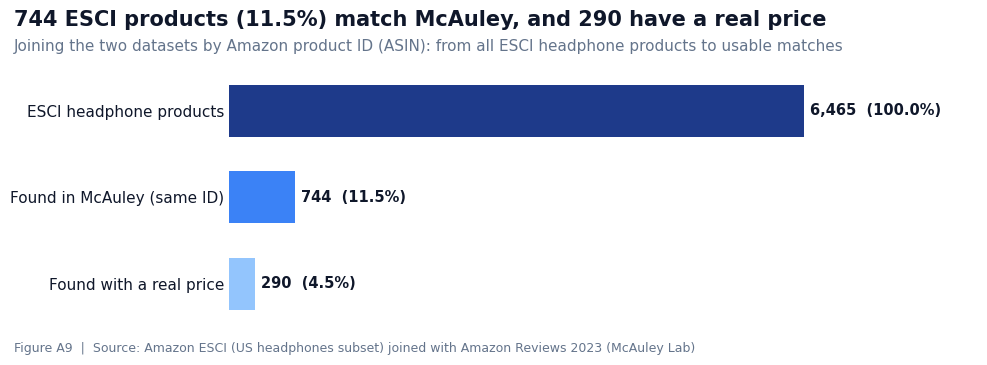

All numbers saved to stats_all.json ✅


In [22]:
# ============================================================
# STEP 11: A9. Join ESCI and McAuley by product ID (ASIN)
# ============================================================

# --- 11.1 Which ESCI products exist in McAuley? ---
mc_ids = set(mc_products["parent_asin"])
matched = esci_products["product_id"].isin(mc_ids)
matched_mc = mc_products[mc_products["parent_asin"].isin(set(esci_products["product_id"]))]

# --- 11.2 One joined table: search + label + ESCI text + McAuley price/ratings/specs ---
joined = (esci_pairs
          .merge(esci_products.drop(columns=["product_locale"]), on="product_id", how="left")
          .merge(mc_products.rename(columns={"parent_asin": "product_id", "title": "mcauley_title"}),
                 on="product_id", how="left"))

STATS["join"] = {
    "esci_headphone_products": int(len(esci_products)),
    "found_in_mcauley":        int(matched.sum()),
    "found_pct":               round(float(matched.mean() * 100), 1),
    "found_with_price":        int(matched_mc["price"].notna().sum()),
    "joined_rows":             int(len(joined)),
    "joined_rows_with_price":  int(joined["price"].notna().sum()),
}
J = STATS["join"]

joined.to_parquet(f"{OUT_DIR}/esci_mcauley_joined.parquet", index=False)

display(pd.DataFrame({"Value": [f"{J['esci_headphone_products']:,}", f"{J['found_in_mcauley']:,}",
                                f"{J['found_pct']}%", f"{J['found_with_price']:,}",
                                f"{J['joined_rows']:,}", f"{J['joined_rows_with_price']:,}"]},
                     index=["ESCI headphone products", "Found in McAuley (same ID)", "Match rate",
                            "Found with a real price", "Joined search–product rows",
                            "Joined rows with a price"]))

# --- 11.3 Figure: funnel from ESCI products to usable matched products ---
stages = ["ESCI headphone products", "Found in McAuley (same ID)", "Found with a real price"]
values = [J["esci_headphone_products"], J["found_in_mcauley"], J["found_with_price"]]

fig, ax = plt.subplots(figsize=(10, 3.6))
y = np.arange(len(stages))[::-1]
ax.barh(y, values, height=0.6, color=[NAVY, BLUE, LIGHT])
for yi, v in zip(y, values):
    share = v / values[0] * 100
    ax.text(v + values[0] * 0.01, yi, f"{v:,}  ({share:.1f}%)", va="center", fontsize=10.5, fontweight="bold")
ax.set_yticks(y, stages)
ax.set_xlim(0, values[0] * 1.3)
ax.set_xticks([])
style_axes(ax)

finish(fig, "A9",
       title=f"{J['found_in_mcauley']:,} ESCI products ({J['found_pct']}%) match McAuley, and {J['found_with_price']:,} have a real price",
       subtitle="Joining the two datasets by Amazon product ID (ASIN): from all ESCI headphone products to usable matches",
       source="Amazon ESCI (US headphones subset) joined with Amazon Reviews 2023 (McAuley Lab)",
       filename="join_funnel")

# --- 11.4 Save all numbers so far ---
json.dump(STATS, open(f"{OUT_DIR}/stats_all.json", "w"), indent=1)
print("All numbers saved to stats_all.json ✅")

**So what?**
- **Research:** The join links real shopper searches (ESCI) with real prices, ratings and specs (McAuley).
  The matched products are the pool for our experiment catalog, so the catalog uses real products,
  not invented ones.
- **Limitation:** The match rate is low because of parent vs. variant product IDs. Population-level
  findings (A1–A8) use each dataset at full size; the matched set is used only where both are needed.

# Part B: AI Shelf Readiness Audit
**Question:** Do real listings contain the information real shoppers ask for,
in a form an AI shopping agent can use?

## Step 12: B1. Shopper Intent Map (demand side)
We tag each of the 680 real headphone searches with the requirements it contains:
budget, wireless, noise cancelling, device compatibility, use case, form factor, brand, other features.
We also flag searches that are really for **accessories** (cases, chargers, ear pads), not headphones.
Tagging uses transparent keyword rules; their accuracy is checked in the validation step.

All headphone searches: 680 | Accessory searches: 202 (29.7%) | Searches for headphones themselves: 478


,Headphone searches (%)
Wireless / Bluetooth,31.0
Brand,25.7
Device compatibility,18.0
"Other feature (mic, waterproof, bass…)",17.6
Use case / activity,13.2
Noise cancelling,4.4
Form factor,3.6
Budget / price,1.0


Requirements per search (%): {'0': 17.6, '1': 54.0, '2': 25.1, '3+': 3.3}

Examples (headphone searches only):
  Wireless / Bluetooth: ['sony bluetooth headset', 'wireless earbuds for galaxy 10 plus', 'earphones for tv listening wireless']
  Brand: ['bose headphones', 'sony wireless headphones', 'hyperx cloud headset ps4']
  Device compatibility: ['iphone 6 plus earphones apple original', 'iphone 7 headphones', 'headphones for computer with microphone']
  Other feature (mic, waterproof, bass…): ['3.5mm microphone and headphone split cheap', 'usb headphones without microphone', 'pc headset without microphone']
  Use case / activity: ['gaming headset for kids', 'ls10x wired gaming headset', 'top rated bluetooth sports water proof ear headphones']
  Noise cancelling: ['noise cancelling headphones under 20', 'headset noise cancelling microphone wireless', 'bose night noise cancelling headphones']
  Form factor: ['bluetooth headphones over ear', 'over-ear headphones', 'headphones for kids w

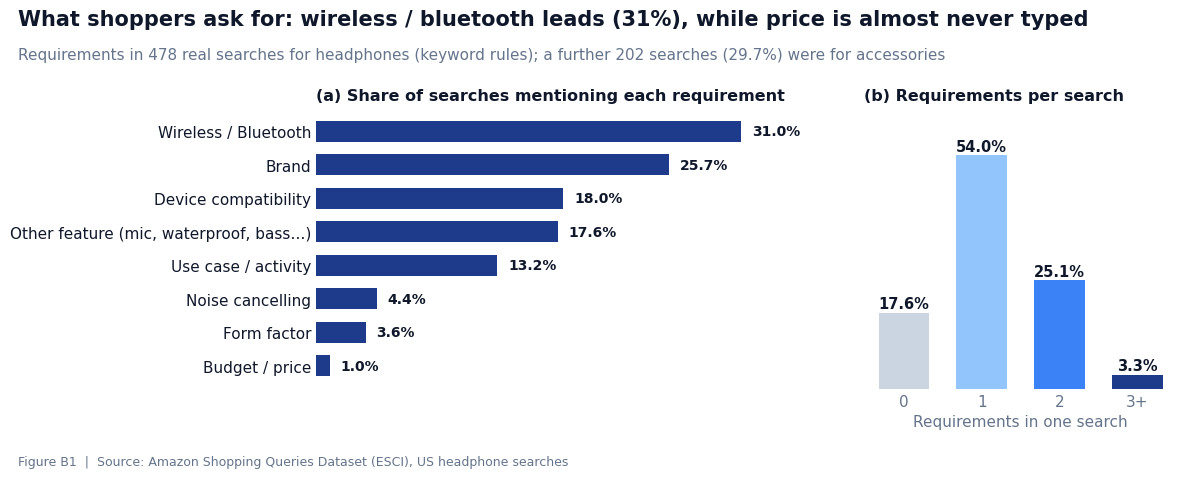

In [24]:
# ============================================================
# STEP 12: B1. Shopper Intent Map (680 real headphone searches)
# ============================================================

# --- 12.1 Keyword rules for each type of requirement ---
INTENTS = {
    "Wireless / Bluetooth": r"wireless|bluetooth|cordless|\btws\b",
    "Noise cancelling":     r"noise[\s-]*(?:cancel|reduc)|\banc\b",
    "Device compatibility": r"iphone|android|\bps[45]\b|playstation|xbox|nintendo|\bswitch\b|\bpc\b|laptop|ipad|computer|\btv\b|\bmac\b|\bphone\b",
    "Use case / activity":  r"running|sport|gym|workout|gaming|gamer|sleep|travel|office|kids?\b|child|swim|study|school|call|zoom|work\b",
    "Form factor":          r"over[\s-]?ear|on[\s-]?ear|in[\s-]?ear|bone conduction|open[\s-]?ear|neckband|ear ?hook",
    "Brand":                r"sony|bose|apple|airpods?|beats|jbl|samsung|skullcandy|sennheiser|jabra|anker|soundcore|razer|hyperx|logitech|steelseries|audio[\s-]?technica|panasonic|plantronics|corsair|turtle beach|tozo|raycon|master dynamics|marshall|bang|google|pixel",
    "Budget / price":       r"\bunder\s*\$?\d+|\bbelow\s*\$?\d+|\bless than\b|cheap|budget|affordable|\$\s?\d+",
    "Other feature (mic, waterproof, bass…)": r"\bmic\b|microphone|waterproof|water[\s-]?resistant|sweat|\bipx|battery|bass|volume|wired|usb|3\.5",
}
# searches for accessories, not headphones (word boundaries avoid e.g. "standard")
ACCESSORY_SEARCH = (r"\b(?:case|cases|cover|covers|charger|charging|cable|cord|replacement|ear ?pads?|ear ?tips?|"
                    r"soft tips|tips|adapter|stand|holder|cushions?|skin|skins|strap|accessories|hook)\b")

# --- 12.2 Tag every search ---
intent_tags = headphone_searches[["query_id", "query"]].copy()
for name, pattern in INTENTS.items():
    intent_tags[name] = intent_tags["query"].str.contains(pattern, case=False, regex=True)
intent_tags["Accessory search"] = intent_tags["query"].str.contains(ACCESSORY_SEARCH, case=False, regex=True)

intent_cols = list(INTENTS)
intent_tags["n_requirements"] = intent_tags[intent_cols].sum(axis=1)
intent_tags.to_parquet(f"{OUT_DIR}/search_intents.parquet", index=False)

# --- 12.3 Demand map uses ONLY searches for headphones themselves ---
product_searches = intent_tags[~intent_tags["Accessory search"]]
n_all, n_product = len(intent_tags), len(product_searches)
accessory_pct = round(float(intent_tags["Accessory search"].mean() * 100), 1)

intent_pct = (product_searches[intent_cols].mean() * 100).round(1).sort_values(ascending=False)
req_groups = pd.cut(product_searches["n_requirements"], bins=[-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"])
req_share = (req_groups.value_counts(normalize=True).sort_index() * 100).round(1)

STATS["intent"] = {"n_searches": int(n_all), "n_product_searches": int(n_product),
                   "accessory_search_pct": accessory_pct,
                   "intent_pct": intent_pct.to_dict(),
                   "requirements_per_search_pct": req_share.to_dict()}

print(f"All headphone searches: {n_all} | Accessory searches: {n_all - n_product} ({accessory_pct}%) "
      f"| Searches for headphones themselves: {n_product}")
display(intent_pct.rename("Headphone searches (%)").to_frame())
print("Requirements per search (%):", req_share.to_dict())

# --- 12.4 Real examples for each requirement (for transparency) ---
print("\nExamples (headphone searches only):")
for name in intent_pct.index:
    pool = product_searches.loc[product_searches[name], "query"]
    print(f"  {name}: {pool.sample(min(3, len(pool)), random_state=1).tolist()}")
print("\nExamples of accessory searches:",
      intent_tags.loc[intent_tags["Accessory search"], "query"].sample(5, random_state=1).tolist())

# --- 12.5 Figure: two panels ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.7, 1]})

y = np.arange(len(intent_pct))[::-1]
ax1.barh(y, intent_pct.values, height=0.62, color=NAVY)
for yi, v in zip(y, intent_pct.values):
    ax1.text(v + 0.8, yi, f"{v:.1f}%", va="center", fontsize=10, fontweight="bold")
ax1.set_yticks(y, intent_pct.index)
ax1.set_xlim(0, intent_pct.max() * 1.25)
ax1.set_xticks([])
ax1.set_title("(a) Share of searches mentioning each requirement", loc="left", fontsize=11.5, fontweight="bold")
style_axes(ax1)

ax2.bar(req_share.index.astype(str), req_share.values, color=[GRAY, LIGHT, BLUE, NAVY], width=0.65)
for i, v in enumerate(req_share.values):
    ax2.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=10.5, fontweight="bold")
ax2.set_ylim(0, req_share.max() * 1.2)
ax2.set_yticks([])
ax2.set_xlabel("Requirements in one search")
ax2.set_title("(b) Requirements per search", loc="left", fontsize=11.5, fontweight="bold")
style_axes(ax2)

top_name, top_val = intent_pct.index[0], intent_pct.iloc[0]
finish(fig, "B1",
       title=f"What shoppers ask for: {top_name.lower()} leads ({top_val:.0f}%), while price is almost never typed",
       subtitle=f"Requirements in {n_product} real searches for headphones (keyword rules); "
                f"a further {n_all - n_product} searches ({accessory_pct}%) were for accessories",
       source="Amazon Shopping Queries Dataset (ESCI), US headphone searches",
       filename="shopper_intent_map")

**So what?**
- **Research:** These are the requirements real shoppers type into searches. Our experiment tasks follow these
  real patterns, and the most-asked requirements get the most weight in the readiness score (B5).
- **Price nuance:** Shoppers almost never type a price; budgets are applied through filters after searching.
  So price matters for the final choice even though it rarely appears in the search text.
- **Business:** About 1 in 3 "headphone" searches is for accessories, and a large share name a brand or a device.
  Listings that state brand, connectivity and device compatibility match the most searches.

## Step 13: B2. Demand vs. supply
For each requirement from B1, we compare:
- **Demand:** % of real headphone searches that ask for it (B1)
- **Supply:** % of headphone listings that state it

Supply uses the **same keyword rules** as demand, applied to the listing text,
except Brand (brand/store field filled) and Price (price field filled).
McAuley is the main supply source (it has price and specs); ESCI is shown as a check.

,Demand: searches (%),Fact type,Supply: McAuley listings (%),Supply: ESCI listings (%),Information gap
Wireless / Bluetooth,31.0,Universal,89.5,78.4,False
Brand,25.7,Universal,99.6,99.3,False
Device compatibility,18.0,Universal,51.9,53.7,True
"Other feature (mic, waterproof, bass…)",17.6,Optional,85.6,69.3,False
Use case / activity,13.2,Optional,60.8,67.6,False
Noise cancelling,4.4,Optional,26.7,25.5,False
Form factor,3.6,Universal,72.1,38.5,False
Budget / price,1.0,Universal,23.3,NaN,True


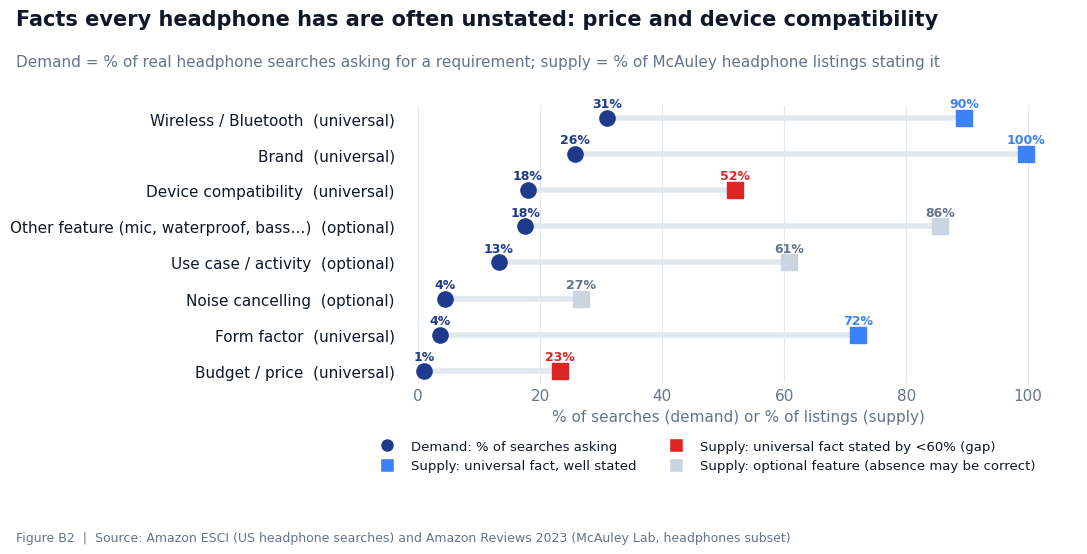

Information gaps (universal facts stated by fewer than 60% of listings): ['Budget / price', 'Device compatibility']


In [26]:
# ============================================================
# STEP 13: B2. Demand (searches) vs. Supply (listings)
# ============================================================

# --- 13.1 Universal facts (every headphone has a value) vs optional features ---
FACT_TYPE = {
    "Wireless / Bluetooth": "Universal",   # every headphone is wired or wireless
    "Brand":                "Universal",
    "Device compatibility": "Universal",   # every headphone works with some device
    "Form factor":          "Universal",   # every headphone has a form factor
    "Budget / price":       "Universal",   # every product has a price
    "Noise cancelling":     "Optional",    # many headphones don't have it
    "Use case / activity":  "Optional",
}
def fact_type(name):
    return FACT_TYPE.get(name, "Optional")   # "Other feature" → Optional

# supply for connectivity = listing states wired OR wireless (both are valid answers)
CONNECTIVITY_STATED = r"wireless|bluetooth|wired|cable|corded|3\.5|\baux\b|usb|jack"

# --- 13.2 Supply: % of listings that state each requirement ---
def supply_share(name):
    if name == "Brand":
        mc = (~is_empty(mc_products["store"])).mean()
        esci = (~is_empty(esci_products["product_brand"])).mean()
    elif name == "Budget / price":
        mc, esci = mc_products["price"].notna().mean(), np.nan     # ESCI has no price field
    else:
        pattern = CONNECTIVITY_STATED if name == "Wireless / Bluetooth" else INTENTS[name]
        mc = mc_text.str.contains(pattern, regex=True).mean()
        esci = esci_text.str.contains(pattern, regex=True).mean()
    return round(mc * 100, 1), (round(esci * 100, 1) if pd.notna(esci) else np.nan)

GAP_THRESHOLD = 60   # a universal fact stated by fewer than 60% of listings = information gap

gap_table = pd.DataFrame({"Demand: searches (%)": intent_pct})
gap_table["Fact type"] = [fact_type(n) for n in gap_table.index]
gap_table[["Supply: McAuley listings (%)", "Supply: ESCI listings (%)"]] = [
    supply_share(n) for n in gap_table.index]
gap_table["Information gap"] = [
    (t == "Universal") and (s < GAP_THRESHOLD)
    for t, s in zip(gap_table["Fact type"], gap_table["Supply: McAuley listings (%)"])]

STATS["demand_supply"] = gap_table.to_dict()
display(gap_table)

# --- 13.3 Figure: dumbbell chart ---
fig, ax = plt.subplots(figsize=(11, 5.6))
rows = gap_table.sort_values("Demand: searches (%)")
y = np.arange(len(rows))

for yi, (name, r) in zip(y, rows.iterrows()):
    d, s = r["Demand: searches (%)"], r["Supply: McAuley listings (%)"]
    color = GRAY if r["Fact type"] == "Optional" else (RED if r["Information gap"] else BLUE)
    ax.plot([d, s], [yi, yi], color=GRID, linewidth=4, zorder=1)
    ax.scatter(d, yi, s=120, color=NAVY, zorder=3)
    ax.scatter(s, yi, s=120, color=color, marker="s", zorder=3)
    ax.text(d, yi + 0.3, f"{d:.0f}%", ha="center", fontsize=9, color=NAVY, fontweight="bold")
    ax.text(s, yi + 0.3, f"{s:.0f}%", ha="center", fontsize=9,
            color=MUTED if color == GRAY else color, fontweight="bold")

labels = [f"{n}  ({'optional' if fact_type(n) == 'Optional' else 'universal'})" for n in rows.index]
ax.set_yticks(y, labels)
ax.set_xlim(-3, 108)
ax.set_xlabel("% of searches (demand) or % of listings (supply)")
ax.legend(handles=[
    plt.Line2D([], [], marker="o", color="w", markerfacecolor=NAVY, markersize=10, label="Demand: % of searches asking"),
    plt.Line2D([], [], marker="s", color="w", markerfacecolor=BLUE, markersize=10, label="Supply: universal fact, well stated"),
    plt.Line2D([], [], marker="s", color="w", markerfacecolor=RED, markersize=10, label=f"Supply: universal fact stated by <{GAP_THRESHOLD}% (gap)"),
    plt.Line2D([], [], marker="s", color="w", markerfacecolor=GRAY, markersize=10, label="Supply: optional feature (absence may be correct)")],
    loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=2, fontsize=9.5)
style_axes(ax, grid="x")

gaps = rows[rows["Information gap"]].index.tolist()
gap_text = " and ".join(g.split(" / ")[-1].lower() if g == "Budget / price" else g.lower() for g in gaps)
finish(fig, "B2",
       title=f"Facts every headphone has are often unstated: {gap_text}" if gaps
             else "Universal facts are well stated; gaps are in optional features",
       subtitle="Demand = % of real headphone searches asking for a requirement; supply = % of McAuley headphone listings stating it",
       source="Amazon ESCI (US headphone searches) and Amazon Reviews 2023 (McAuley Lab, headphones subset)",
       filename="demand_vs_supply")
print("Information gaps (universal facts stated by fewer than "
      f"{GAP_THRESHOLD}% of listings):", gaps)

**So what?**
- **Method:** We separate **universal facts** (every headphone has a value: price, connectivity, compatibility,
  form factor, brand) from **optional features** (noise cancelling, use case). For universal facts, not stating
  them is missing information; for optional features, absence may simply mean the product lacks the feature.
- **Research:** The red squares are universal facts shoppers need but most listings don't state. These are
  the fields most likely to make an AI agent drop or mis-rank a product, so our experiment manipulates them.
- **Business:** Every red square is a free fix: the product already HAS a price and a compatible device;
  the listing just doesn't say so.
- **Note:** "Device compatibility" here means any device (phone, PC, TV, console), so it is higher than
  A4's 27–28%, which counts only iPhone/Android mentions.

## Step 14: B3. Defect Profile: how readable are key facts for an AI agent?
For each universal fact, every listing is classified as:
- **Clear:** stated once, with a usable value
- **Ambiguous (several figures):** different numbers for the same fact (e.g. "8H" and "32H"); the agent must guess which applies → *inconsistent*
- **Vague:** mentioned without a number (e.g. "long-lasting battery") → *unclear*
- **Missing:** not stated at all → *missing*

We also measure **format variety**: the share of listings writing hours in a non-standard way ("40H", "40hrs" vs "40 hours").
Battery life is measured on wireless listings only (wired headphones have no battery).

,Clear (one figure),Ambiguous (several figures),Vague (no number),Missing
Price,23.3,0.0,0.0,76.7
Device compatibility,51.9,0.0,0.0,48.1
Battery life (wireless only),17.9,25.4,3.8,52.9


Wireless listings analysed for battery: 32,039
Of listings with an hours figure, 36.2% use a non-standard format (not '40 hours')


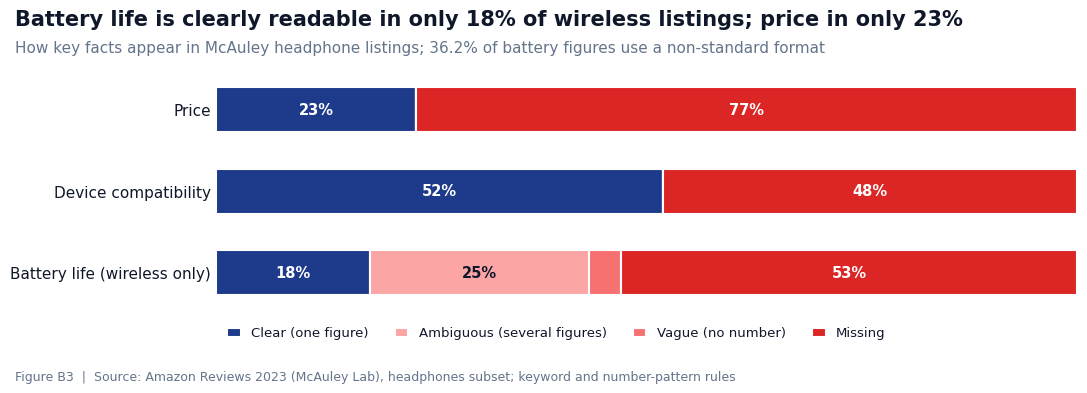

In [27]:
# ============================================================
# STEP 14: B3. Defect Profile (McAuley headphones)
# ============================================================

# --- 14.1 Battery life: classify every wireless listing ---
VAGUE_BATTERY = re.compile(
    r"long[\s-]?lasting|long battery|all[\s-]?day|extended (?:battery|playtime)|long playtime|ultra[\s-]?long|marathon", re.I)

def battery_status(text):
    """Return (status, uses_nonstandard_format) for one listing."""
    values, formats = set(), set()
    for m in HOURS_PATTERN.finditer(text):          # same hours pattern as A5
        value = float(m.group(1))
        if 1 <= value <= 200:                        # ignore implausible numbers
            values.add(value)
            formats.add(format_of(m))
    if len(values) == 1:
        status = "Clear (one figure)"
    elif len(values) > 1:
        status = "Ambiguous (several figures)"
    elif VAGUE_BATTERY.search(text):
        status = "Vague (no number)"
    else:
        status = "Missing"
    nonstandard = bool(formats) and any(f != "40 hours" for f in formats)
    return status, nonstandard

is_wireless = mc_text.str.contains(r"wireless|bluetooth", regex=True)
wireless = mc_products[is_wireless]
wireless_text = (wireless["title"] + " " + wireless["features"] + " " +
                 wireless["description"] + " " + wireless["details"])
results = wireless_text.apply(battery_status)
battery = results.str[0]
nonstandard = results.str[1]

has_figure = battery.isin(["Clear (one figure)", "Ambiguous (several figures)"])
nonstandard_pct = round(float(nonstandard[has_figure].mean() * 100), 1)

# --- 14.2 Price and device compatibility (stated vs missing) ---
price_clear = mc_products["price"].notna().mean() * 100
compat_clear = mc_text.str.contains(INTENTS["Device compatibility"], regex=True).mean() * 100

# --- 14.3 One table: % of listings in each category ---
CATEGORIES = ["Clear (one figure)", "Ambiguous (several figures)", "Vague (no number)", "Missing"]
defects = pd.DataFrame(0.0, index=["Price", "Device compatibility", "Battery life (wireless only)"],
                       columns=CATEGORIES)
defects.loc["Price", ["Clear (one figure)", "Missing"]] = [price_clear, 100 - price_clear]
defects.loc["Device compatibility", ["Clear (one figure)", "Missing"]] = [compat_clear, 100 - compat_clear]
defects.loc["Battery life (wireless only)"] = (battery.value_counts(normalize=True)
                                               .reindex(CATEGORIES).fillna(0) * 100).values
defects = defects.round(1)

STATS["defects"] = {"table_pct": defects.to_dict(), "wireless_listings": int(len(wireless)),
                    "battery_nonstandard_format_pct": nonstandard_pct}
display(defects)
print(f"Wireless listings analysed for battery: {len(wireless):,}")
print(f"Of listings with an hours figure, {nonstandard_pct}% use a non-standard format (not '40 hours')")

# --- 14.4 Figure: 100% stacked bars ---
COLORS = {"Clear (one figure)": NAVY, "Ambiguous (several figures)": "#FCA5A5",
          "Vague (no number)": "#F87171", "Missing": RED}
fig, ax = plt.subplots(figsize=(11, 3.9))
y = np.arange(len(defects))[::-1]
left = np.zeros(len(defects))
for cat in CATEGORIES:
    vals = defects[cat].values
    ax.barh(y, vals, left=left, height=0.55, color=COLORS[cat], edgecolor="white", linewidth=1.5, label=cat)
    for yi, start, v in zip(y, left, vals):
        if v >= 6:
            ax.text(start + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=10.5,
                    fontweight="bold", color="white" if cat in ["Clear (one figure)", "Missing"] else INK)
    left += vals
ax.set_yticks(y, defects.index)
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.04), handlelength=1, fontsize=9.5)
style_axes(ax)

clear_battery = defects.loc["Battery life (wireless only)", "Clear (one figure)"]
finish(fig, "B3",
       title=f"Battery life is clearly readable in only {clear_battery:.0f}% of wireless listings; price in only {price_clear:.0f}%",
       subtitle=f"How key facts appear in McAuley headphone listings; {nonstandard_pct}% of battery figures use a non-standard format",
       source="Amazon Reviews 2023 (McAuley Lab), headphones subset; keyword and number-pattern rules",
       filename="defect_profile")

## Step 15: B4. Agent-Readiness Score (ARS)
**ARS (0–100)** = share of 7 key facts an AI agent can read from the listing:
1. Price stated  2. Connectivity stated (wired/wireless)  3. Device compatibility stated
4. Form factor stated  5. Brand stated  6. Battery life clear (wireless only; not applicable to wired)
7. Description present

**Main version:** equal weights (simple and transparent).
**Sensitivity check:** demand-weighted version (weights from B1). If both rank products almost the same,
the score does not depend on our weighting choice.

**Second question:** do less popular products (fewer ratings) have less agent-ready data?

,Products passing (%)
Price stated,23.3
Connectivity stated,89.5
Compatibility stated,51.9
Form factor stated,72.1
Brand stated,99.6
Battery life clear,59.9
Description present,56.3


Mean ARS: 64.6 | Median ARS: 71.4
Equal vs demand-weighted ranking agreement (Spearman): 0.971
Mean ARS by number of ratings: {'0–9': 59.9, '10–99': 66.5, '100–999': 69.1, '1,000+': 72.6}
Ratings vs ARS (Spearman): 0.227


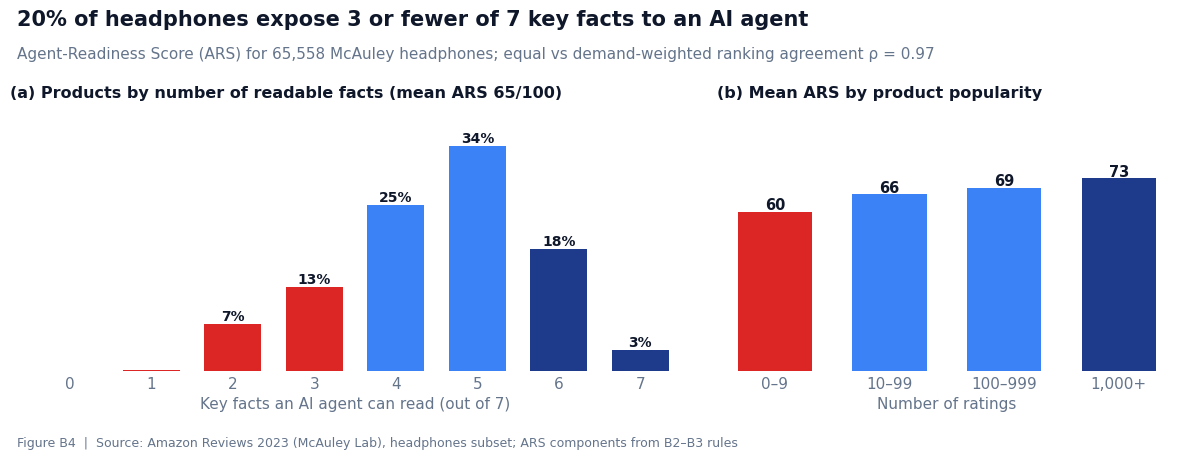

In [28]:
# ============================================================
# STEP 15: B4. Agent-Readiness Score (McAuley headphones)
# ============================================================
from scipy.stats import spearmanr

# --- 15.1 The 7 components (True = an AI agent can read this fact) ---
battery_clear = pd.Series(False, index=mc_products.index)
battery_clear.loc[wireless.index] = (battery == "Clear (one figure)").values

components = pd.DataFrame({
    "Price stated":         mc_products["price"].notna(),
    "Connectivity stated":  mc_text.str.contains(CONNECTIVITY_STATED, regex=True),
    "Compatibility stated": mc_text.str.contains(INTENTS["Device compatibility"], regex=True),
    "Form factor stated":   mc_text.str.contains(INTENTS["Form factor"], regex=True),
    "Brand stated":         ~is_empty(mc_products["store"]),
    "Battery life clear":   (~is_wireless) | battery_clear,     # wired headphones: not applicable → counts as OK
    "Description present":  ~is_empty(mc_products["description"]),
}, index=mc_products.index)

# --- 15.2 Main score: equal weights ---
mc_products["ARS"] = (components.mean(axis=1) * 100).round(1)
mc_products["facts_readable"] = components.sum(axis=1)

# --- 15.3 Sensitivity: demand-weighted score (weights from B1) ---
w = {"Connectivity stated":  intent_pct["Wireless / Bluetooth"],
     "Brand stated":         intent_pct["Brand"],
     "Compatibility stated": intent_pct["Device compatibility"],
     "Form factor stated":   intent_pct["Form factor"]}
avg_w = float(np.mean(list(w.values())))
for c in ["Price stated", "Battery life clear", "Description present"]:   # not typed in searches → average weight
    w[c] = avg_w
weights = pd.Series(w)[components.columns]
mc_products["ARS_demand"] = (components.mul(weights).sum(axis=1) / weights.sum() * 100).round(1)
rho = spearmanr(mc_products["ARS"], mc_products["ARS_demand"]).correlation

# --- 15.4 Does readiness differ by popularity? ---
pop_group = pd.cut(mc_products["rating_number"], bins=[0, 10, 100, 1000, np.inf], right=False,
                   labels=["0–9", "10–99", "100–999", "1,000+"])
ars_by_pop = mc_products.groupby(pop_group, observed=True)["ARS"].mean().round(1)
rho_pop = spearmanr(mc_products["rating_number"], mc_products["ARS"], nan_policy="omit").correlation

STATS["ars"] = {
    "mean": round(float(mc_products["ARS"].mean()), 1),
    "median": float(mc_products["ARS"].median()),
    "component_pass_pct": (components.mean() * 100).round(1).to_dict(),
    "facts_readable_pct": (mc_products["facts_readable"].value_counts(normalize=True).sort_index() * 100).round(1).to_dict(),
    "spearman_equal_vs_demand": round(float(rho), 3),
    "ars_by_popularity": ars_by_pop.to_dict(),
    "spearman_ratings_vs_ars": round(float(rho_pop), 3),
}
A = STATS["ars"]
display((components.mean() * 100).round(1).rename("Products passing (%)").to_frame())
print(f"Mean ARS: {A['mean']} | Median ARS: {A['median']}")
print(f"Equal vs demand-weighted ranking agreement (Spearman): {A['spearman_equal_vs_demand']}")
print(f"Mean ARS by number of ratings: {A['ars_by_popularity']}")
print(f"Ratings vs ARS (Spearman): {A['spearman_ratings_vs_ars']}")

# --- 15.5 Figure: two panels ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})

# (a) how many of the 7 facts are readable
dist = mc_products["facts_readable"].value_counts(normalize=True).reindex(range(8), fill_value=0) * 100
bar_colors = [RED if k <= 3 else (BLUE if k <= 5 else NAVY) for k in dist.index]
ax1.bar(dist.index.astype(str), dist.values, color=bar_colors, width=0.7)
for i, v in enumerate(dist.values):
    if v > 0.5:
        ax1.text(i, v + 0.6, f"{v:.0f}%", ha="center", fontsize=10, fontweight="bold")
ax1.set_xlabel("Key facts an AI agent can read (out of 7)")
ax1.set_yticks([])
ax1.set_ylim(0, dist.max() * 1.18)
ax1.set_title(f"(a) Products by number of readable facts (mean ARS {A['mean']:.0f}/100)",
              loc="left", fontsize=11.5, fontweight="bold")
style_axes(ax1)

# (b) mean ARS by popularity
ax2.bar(ars_by_pop.index.astype(str), ars_by_pop.values, color=[RED, BLUE, BLUE, NAVY], width=0.65)
for i, v in enumerate(ars_by_pop.values):
    ax2.text(i, v + 1, f"{v:.0f}", ha="center", fontsize=10.5, fontweight="bold")
ax2.set_ylim(0, 100)
ax2.set_yticks([])
ax2.set_xlabel("Number of ratings")
ax2.set_title("(b) Mean ARS by product popularity", loc="left", fontsize=11.5, fontweight="bold")
style_axes(ax2)

low_share = dist.loc[0:3].sum()
finish(fig, "B4",
       title=f"{low_share:.0f}% of headphones expose 3 or fewer of 7 key facts to an AI agent",
       subtitle=f"Agent-Readiness Score (ARS) for {len(mc_products):,} McAuley headphones; "
                f"equal vs demand-weighted ranking agreement ρ = {A['spearman_equal_vs_demand']:.2f}",
       source="Amazon Reviews 2023 (McAuley Lab), headphones subset; ARS components from B2–B3 rules",
       filename="agent_readiness_score")

mc_products.to_parquet(f"{OUT_DIR}/mcauley_products.parquet", index=False)   # save with ARS

**So what?**
- **Finding:** Only 3% of headphones expose all 7 key facts; 20% expose 3 or fewer (mean ARS 64.6/100).
- **Robustness:** Equal-weight and demand-weighted scores rank products almost identically (ρ = 0.97),
  so the result does not depend on our weighting choice.
- **Long tail:** ARS rises with popularity (60 → 66 → 69 → 73 from 0–9 to 1,000+ ratings; ρ = 0.23).
  Less-reviewed products are also less readable for AI agents, a possible double disadvantage.
  This is an association, not proof of cause (e.g. bigger brands may have both more reviews and better listings).
- **Business:** ARS is a simple scorecard a seller can compute: "your listing exposes 4 of 7 facts AI shoppers rely on."

## Step 16: B5. Readiness vs. relevance (ESCI)
**Question:** Within the same search, do products judged **Exact** have more agent-readable data
than products judged **Irrelevant**?
- ARS for ESCI uses the same rules, with 6 facts (ESCI has no price field)
- Only searches for headphones and only products that are headphones (not accessories), for a fair comparison
- Paired test within each search: **Wilcoxon signed-rank** (no normality assumption) + effect size
- This shows an **association**; the controlled experiment tests **causation**

,Mean ARS,Pairs
label,,
Exact,70.7,4225
Substitute,70.2,1327
Complement,61.8,17
Irrelevant,76.6,154


Searches with both Exact and Irrelevant headphones: 63
Exact − Irrelevant ARS: mean -2.1, median -5.6
Exact higher in 36.5% of searches; equal in 1.6%
Wilcoxon p = 0.1557 | effect size (rank-biserial r) = -0.207


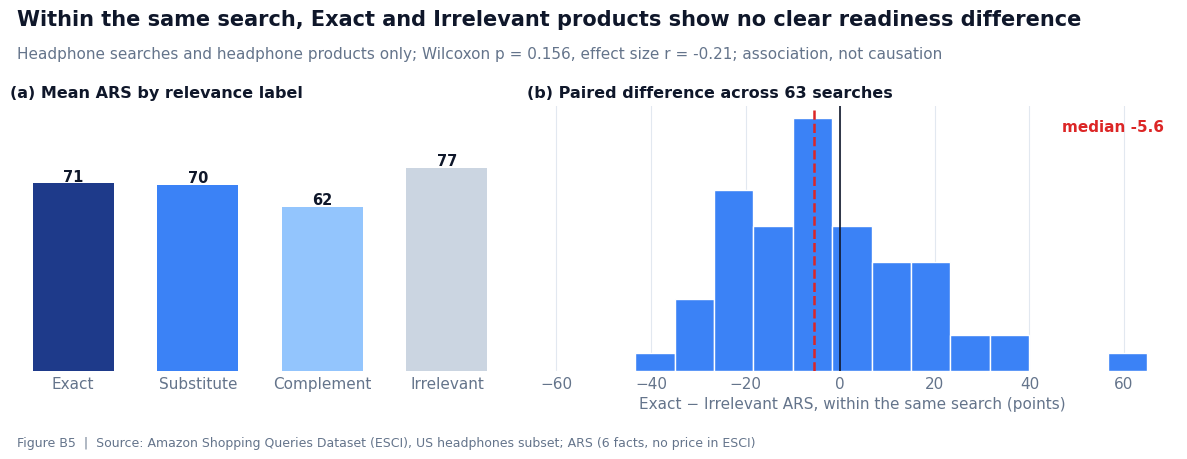

In [30]:
# ============================================================
# STEP 16: B5. Readiness vs. relevance (ESCI, within the same search)
# ============================================================
from scipy.stats import wilcoxon

# --- 16.1 ARS for ESCI products (6 facts; no price field in ESCI) ---
esci_raw_text = (esci_products["product_title"].fillna("") + " " +
                 esci_products["product_bullet_point"].fillna("") + " " +
                 esci_products["product_description"].fillna(""))
esci_is_wireless = esci_text.str.contains(r"wireless|bluetooth", regex=True)
esci_battery_clear = pd.Series(False, index=esci_products.index)
esci_battery_clear.loc[esci_is_wireless] = (
    esci_raw_text[esci_is_wireless].apply(battery_status).str[0] == "Clear (one figure)").values

esci_components = pd.DataFrame({
    "Connectivity stated":  esci_text.str.contains(CONNECTIVITY_STATED, regex=True),
    "Compatibility stated": esci_text.str.contains(INTENTS["Device compatibility"], regex=True),
    "Form factor stated":   esci_text.str.contains(INTENTS["Form factor"], regex=True),
    "Brand stated":         ~is_empty(esci_products["product_brand"]),
    "Battery life clear":   (~esci_is_wireless) | esci_battery_clear,
    "Description present":  ~is_empty(esci_products["product_description"]),
}, index=esci_products.index)
esci_products["ARS"] = (esci_components.mean(axis=1) * 100).round(1)

# --- 16.2 Keep only headphone products (same rule as McAuley, using the title) ---
esci_products["is_headphone"] = esci_products["product_title"].fillna("").apply(
    lambda t: is_headphone_product(t, ""))

# --- 16.3 Join with labels; only headphone searches and headphone products ---
pairs = (esci_pairs[esci_pairs["query_id"].isin(product_searches["query_id"])]
         .merge(esci_products[["product_id", "ARS", "is_headphone"]], on="product_id"))
pairs = pairs[pairs["is_headphone"]].copy()
pairs["label"] = pairs["esci_label"].map(LABEL_NAMES)

mean_by_label = pairs.groupby("label")["ARS"].mean().reindex(ORDER).round(1)
count_by_label = pairs["label"].value_counts().reindex(ORDER)

# --- 16.4 Paired comparison within each search: Exact vs Irrelevant ---
per_search = pairs.groupby(["query_id", "label"])["ARS"].mean().unstack()
paired = per_search[["Exact", "Irrelevant"]].dropna()
diff = paired["Exact"] - paired["Irrelevant"]

test = wilcoxon(paired["Exact"], paired["Irrelevant"])
nonzero = diff[diff != 0]
ranks = nonzero.abs().rank()
effect_r = float((ranks[nonzero > 0].sum() - ranks[nonzero < 0].sum()) / ranks.sum())   # rank-biserial

STATS["relevance"] = {
    "pairs_used": int(len(pairs)),
    "mean_ars_by_label": mean_by_label.to_dict(),
    "n_by_label": count_by_label.to_dict(),
    "searches_with_both": int(len(paired)),
    "median_diff_exact_minus_irrelevant": round(float(diff.median()), 1),
    "mean_diff_exact_minus_irrelevant": round(float(diff.mean()), 1),
    "pct_searches_exact_higher": round(float((diff > 0).mean() * 100), 1),
    "pct_searches_equal": round(float((diff == 0).mean() * 100), 1),
    "wilcoxon_p": float(test.pvalue),
    "effect_size_rank_biserial": round(effect_r, 3),
}
R = STATS["relevance"]
display(pd.DataFrame({"Mean ARS": mean_by_label, "Pairs": count_by_label}))
print(f"Searches with both Exact and Irrelevant headphones: {R['searches_with_both']}")
print(f"Exact − Irrelevant ARS: mean {R['mean_diff_exact_minus_irrelevant']}, median {R['median_diff_exact_minus_irrelevant']}")
print(f"Exact higher in {R['pct_searches_exact_higher']}% of searches; equal in {R['pct_searches_equal']}%")
print(f"Wilcoxon p = {R['wilcoxon_p']:.4f} | effect size (rank-biserial r) = {R['effect_size_rank_biserial']}")

# --- 16.5 Figure: two panels ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})

ax1.bar(mean_by_label.index, mean_by_label.values, color=[NAVY, BLUE, LIGHT, GRAY], width=0.65)
for i, v in enumerate(mean_by_label.values):
    ax1.text(i, v + 1, f"{v:.0f}", ha="center", fontsize=10.5, fontweight="bold")
ax1.set_ylim(0, 100)
ax1.set_yticks([])
ax1.set_title("(a) Mean ARS by relevance label", loc="left", fontsize=11.5, fontweight="bold")
style_axes(ax1)

ax2.hist(diff, bins=np.arange(-60, 65, 8.33), color=BLUE, edgecolor="white")
ax2.axvline(0, color=INK, linewidth=1.2)
ax2.axvline(diff.median(), color=RED, linestyle="--", linewidth=1.8)
ax2.text(0.98, 0.95, f"median {diff.median():+.1f}", transform=ax2.transAxes,
         ha="right", va="top", color=RED, fontweight="bold")
ax2.set_xlabel("Exact − Irrelevant ARS, within the same search (points)")
ax2.set_yticks([])
ax2.set_title(f"(b) Paired difference across {R['searches_with_both']} searches",
              loc="left", fontsize=11.5, fontweight="bold")
style_axes(ax2, grid="x")

significant = R["wilcoxon_p"] < 0.05 and R["median_diff_exact_minus_irrelevant"] >= 0 and R["mean_diff_exact_minus_irrelevant"] > 0
finish(fig, "B5",
       title=("Within the same search, Exact matches are more agent-ready than Irrelevant products"
              if significant else
              "Within the same search, Exact and Irrelevant products show no clear readiness difference"),
       subtitle=f"Headphone searches and headphone products only; Wilcoxon p = {R['wilcoxon_p']:.3f}, "
                f"effect size r = {R['effect_size_rank_biserial']:.2f}; association, not causation",
       source="Amazon Shopping Queries Dataset (ESCI), US headphones subset; ARS (6 facts, no price in ESCI)",
       filename="readiness_vs_relevance")

**So what?**
- **Finding:** Within the same search, Exact and Irrelevant headphone listings show no significant
  difference in agent-readiness (63 searches; Wilcoxon p = 0.156; effect size r = −0.21).
- **Interpretation:** Human relevance labels reflect whether a product matches the search (brand, type),
  not how complete its data is. An "Irrelevant" product can be very well documented.
- **Why this matters for our method:** The effect of data quality cannot be read from existing observational
  labels, because data quality is mixed up with product match. This is exactly why our project uses a
  **controlled experiment**: change one field, hold everything else fixed, and measure the AI agent's response.
- **Limitation:** Only 63 searches contained both labels, so small effects may be undetected.

## Step 17: B6. Selecting the experiment catalog
**Pool:** products found in both ESCI and McAuley, with a real price, that appeared in real headphone searches.
Two-way radio / walkie-talkie earpieces are excluded (not consumer headphones).
**Readiness groups** (by number of the 7 key facts an agent can read, so groups never overlap):
Low = 5 or fewer, Medium = 6, High = all 7.
**Selection:** 5 products per group with a fixed random seed (42), so the catalog is reproducible.
**Next:** the team manually confirms each selected product is a real consumer headphone.

Pool: 283 products → 194 after keeping only single, new, consumer headphones


,count,min,median,max
readiness_group,,,,
Low (≤5 of 7 facts),77,57.1,71.4,71.4
Medium (6 of 7),82,85.7,85.7,85.7
High (7 of 7),35,100.0,100.0,100.0


Selected: 15 products


,parent_asin,title,store,price,average_rating,rating_number,facts_readable,ARS,readiness_group
1883,B07KR62YBD,"Senso Bluetooth Headphones, Best Wireless Spor...",Senso,24.97,4.0,8960,5,71.4,Low (≤5 of 7 facts)
9966,B0916GB3JT,RIG 500 PRO Esports Edition 3D Audio Universal...,RIG,49.99,4.5,110,4,57.1,Low (≤5 of 7 facts)
3031,B07HP1N2RC,SIMOLIO 2.4G Digital TV Wireless Headphones wi...,SIMOLIO,114.99,4.2,1297,5,71.4,Low (≤5 of 7 facts)
27914,B08JD7M5RK,Jabra Evolve2 65 Headset,Jabra,265.98,4.1,31,5,71.4,Low (≤5 of 7 facts)
34696,B08VRLZGMF,Bose Sport Open Earbuds — True Wireless Open E...,Bose,449.99,3.7,2184,5,71.4,Low (≤5 of 7 facts)
11332,B082QPHYZQ,SAMSUNG EO-IC100BBEGUS Corded Type-C Earphones...,SAMSUNG,18.50,4.3,10846,6,85.7,Medium (6 of 7)
57465,B007BTULVG,Monoprice Hi-Fi Light Weight Noise Isolationg ...,Monoprice,27.76,4.1,132,6,85.7,Medium (6 of 7)
38107,B01KFLGL5Q,Arama Cell Phone Headset w/Lightweight Secure-...,Arama,32.99,4.3,2449,6,85.7,Medium (6 of 7)
32747,B00I3LUY68,Sony Foldable Headphones MDR-ZX310 R - Metalli...,Sony,50.00,4.4,5752,6,85.7,Medium (6 of 7)
29050,B072JWYJMC,Jabra Evolve 75 UC Stereo Wireless Bluetooth H...,Jabra,264.98,4.3,1046,6,85.7,Medium (6 of 7)


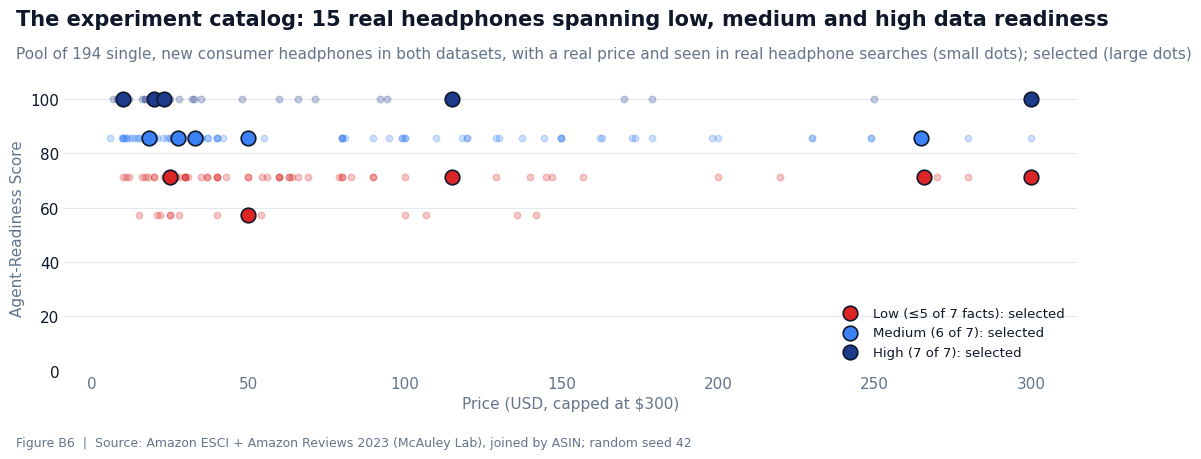

Catalog and all numbers saved to Drive 


In [37]:
# ============================================================
# STEP 17: B6. Experiment catalog selection
# ============================================================

# --- 17.1 Candidate pool ---
ids_in_headphone_searches = set(esci_pairs[esci_pairs["query_id"].isin(product_searches["query_id"])]["product_id"])
pool = mc_products[mc_products["parent_asin"].isin(ids_in_headphone_searches)
                   & mc_products["price"].notna()].copy()

# keep only single, new, consumer headphones
NOT_ELIGIBLE = (r"walkie|talkie|two[\s-]?way|\bradios?\b|baofeng|midland|air ?tube|covert|surveillance" # radio earpieces
                r"|telephone|dial ?pad|landline"                                       # telephones
                r"|\bbulk\b|\d+\s*-?\s*pack|pack of"                                   # multipacks
                r"|renewed|refurbished")                                               # not new


n_before = len(pool)
eligible_text = pool["title"] + " " + pool["store"]
pool = pool[~eligible_text.str.contains(NOT_ELIGIBLE, case=False, regex=True)]
print(f"Pool: {n_before} products → {len(pool)} after keeping only single, new, consumer headphones")

# --- 17.2 Readiness groups by number of readable facts (no overlap) ---
pool["readiness_group"] = pd.cut(pool["facts_readable"], bins=[-1, 5, 6, 7],
                                 labels=["Low (≤5 of 7 facts)", "Medium (6 of 7)", "High (7 of 7)"])
display(pool.groupby("readiness_group", observed=True)["ARS"].agg(["count", "min", "median", "max"]))

# --- 17.3 Pick 5 per group (fixed seed = reproducible) ---
catalog = (pool.groupby("readiness_group", observed=True)
               .sample(n=5, random_state=42)
               .sort_values(["readiness_group", "price"]))

cols = ["parent_asin", "title", "store", "price", "average_rating", "rating_number",
        "facts_readable", "ARS", "readiness_group"]
pool[cols].to_csv(f"{OUT_DIR}/experiment_candidate_pool.csv", index=False)
catalog[cols].to_csv(f"{OUT_DIR}/experiment_catalog_selected.csv", index=False)

STATS["catalog"] = {
    "pool_before_filter": int(n_before),
    "pool_size": int(len(pool)),
    "pool_by_group": pool["readiness_group"].value_counts().to_dict(),
    "selected": int(len(catalog)),
}
print(f"Selected: {len(catalog)} products")

show = catalog[cols].copy()
show["title"] = show["title"].str[:70]
display(show)

# --- 17.4 Figure: pool vs selected products (price vs readiness) ---
fig, ax = plt.subplots(figsize=(11, 4.6))
GROUP_COLORS = dict(zip(pool["readiness_group"].cat.categories, [RED, BLUE, NAVY]))
for grp, color in GROUP_COLORS.items():
    p = pool[pool["readiness_group"] == grp]
    ax.scatter(p["price"].clip(upper=300), p["ARS"], s=22, color=color, alpha=0.25)
    c = catalog[catalog["readiness_group"] == grp]
    ax.scatter(c["price"].clip(upper=300), c["ARS"], s=110, color=color, edgecolor=INK, linewidth=1.2,
               label=f"{grp}: selected")
ax.set_xlabel("Price (USD, capped at $300)")
ax.set_ylabel("Agent-Readiness Score")
ax.set_ylim(0, 105)
ax.legend(loc="lower right", fontsize=9.5)
style_axes(ax, grid="y")

finish(fig, "B6",
       title=f"The experiment catalog: {len(catalog)} real headphones spanning low, medium and high data readiness",
       subtitle=f"Pool of {len(pool)} single, new consumer headphones in both datasets, with a real price and seen in "
                f"real headphone searches (small dots); selected (large dots)",
       source="Amazon ESCI + Amazon Reviews 2023 (McAuley Lab), joined by ASIN; random seed 42",
       filename="experiment_catalog")

json.dump(STATS, open(f"{OUT_DIR}/stats_all.json", "w"), indent=1, default=str)
print("Catalog and all numbers saved to Drive ")

**So what?**
- **Research:** The experiment catalog uses 15 real products, selected by data, not by hand: real searches,
  real prices, and three readiness levels (Low / Medium / High). The fixed seed makes it reproducible.
- **Data quality:** Keyword filters let through radio earpieces, telephones, multipacks and refurbished items,
  so we added explicit eligibility rules and manually checked every selected product.
- **Next:** each experiment condition breaks ONE field of ONE target product, using the defect types
  measured in B3 (missing, vague, ambiguous, non-standard format).

## Executive Summary
**Question:** Do real product listings contain the information real shoppers ask for, in a form an AI shopping agent can use?
**Data:** 680 real headphone searches (Amazon ESCI) + 65,558 headphone listings with price, ratings and specs (Amazon Reviews 2023), joined by product ID.

**Five key findings**
1. **The most important facts are often missing.** 76.7% of headphone listings have no price; 48% don't state which devices they work with.
2. **Battery life is clearly readable in only 18% of wireless listings.** The rest is missing (53%), ambiguous (25%) or vague (4%), and 36% of battery figures use a non-standard format ("40H", "40hrs").
3. **Only 3% of headphones expose all 7 key facts** an AI agent needs (mean Agent-Readiness Score 64.6/100; robust to weighting, ρ = 0.97).
4. **Less-reviewed products are less agent-ready** (score 60 for 0–9 ratings vs 73 for 1,000+): a possible double disadvantage for small sellers.
5. **Data quality cannot be read from existing relevance labels** (Exact vs Irrelevant: no significant difference, p = 0.156), so its effect must be tested with a **controlled experiment**, which this project does.

**Output for the experiment:** a reproducible catalog of 15 real headphones at three readiness levels, and real-world frequencies for the four data defects we test (missing, unclear, inconsistent, different format).

# From EDA to Experiment Design
| EDA finding | Experiment design decision |
|---|---|
| Price missing in 76.7% of listings (A6, B2) | Test **missing price** as a core condition |
| Compatibility stated by only ~half of listings (B2) | Test **missing compatibility** for device-specific tasks |
| Battery: 53% missing, 25% ambiguous, 4% vague (B3) | Test all three battery defects: **missing, ambiguous, vague** |
| 36% of battery figures in non-standard format (A5, B3) | Test **format variation** ("40 hours" vs "40H" vs "40hrs") |
| Wireless, brand and compatibility are the top shopper requirements (B1) | Build tasks around these requirements, from real search patterns |
| Price is rarely typed but budgets matter (B1, A7) | Use realistic budget limits ($50 / $100), since 84.8% of priced headphones are under $100 |
| Data quality is not visible in observational labels (B5) | Use a **controlled design**: change one field, hold everything else fixed |
| Real products differ in readiness (B4, B6) | Catalog of 15 real products at Low / Medium / High readiness |

## Limitations
- **Keyword rules:** requirement tagging, fact detection and the headphone filter use transparent keyword rules,
  which can miss or mis-tag some cases. A manual validation sample is exported for checking (below).
- **Product filter:** the McAuley headphone filter includes some non-headphones (e.g. radios, pens);
  population figures (A6–A8, B2–B4) include this noise. The experiment catalog was manually checked.
- **Join:** only 11.5% of ESCI products match McAuley, because of parent vs variant product IDs.
- **Missing price:** may partly reflect products unavailable when the data was collected.
- **Demand vs supply** use different units (% of searches vs % of listings); B2 shows divergence, not an exact gap.
- **B5** compares only 63 searches, so small effects may be missed.
- **Hours detection** can catch non-battery hours (e.g. "24-hour support").
- **Associations, not causes:** all EDA results are observational; causal claims come from the experiment.

In [39]:
# ============================================================
# STEP 18: Validation sample for manual checking
# ============================================================
val_products = mc_products.sample(100, random_state=7)[["parent_asin", "title", "store", "facts_readable", "ARS"]].copy()
val_products["is_real_headphone (yes/no)"] = ""
val_products["notes"] = ""

val_searches = intent_tags.sample(100, random_state=7)[["query"] + intent_cols + ["Accessory search"]].copy()
val_searches["tags_correct (yes/no)"] = ""
val_searches["notes"] = ""

val_products.to_csv(f"{OUT_DIR}/validation_products_100.csv", index=False)
val_searches.to_csv(f"{OUT_DIR}/validation_searches_100.csv", index=False)
json.dump(STATS, open(f"{OUT_DIR}/stats_all.json", "w"), indent=1, default=str)

print("Validation files saved to Drive ")
print("  validation_products_100.csv: is each product a real headphone?")
print("  validation_searches_100.csv: are the requirement tags correct?")
print("When filled in: precision = share of 'yes' answers → report it in the Limitations section.")

Validation files saved to Drive 
  validation_products_100.csv: is each product a real headphone?
  validation_searches_100.csv: are the requirement tags correct?
When filled in: precision = share of 'yes' answers → report it in the Limitations section.
